# DecPyMC-5-Valeur de l'Information
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jsboige/CoursIA/blob/main/MyIA.AI.Notebooks/Probas/DecisionTheory/DecPyMC/DecPyMC-5-Value-Information.ipynb)

## Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
- Calculer l'**Esperance de Valeur de l'Information Parfaite** (EVPI)
- Calculer l'**Esperance de Valeur de l'Information Sample** (EVSI)
- Evaluer quand une information supplementaire est rentable
- Construire un calculateur generique de valeur de l'information
- Appliquer Bayes pour mettre a jour les croyances après observation

**Prerequis** : DecPyMC-3 (Arbres de decision), bases de calcul bayesien

**Duree estimee** : 45 minutes pour le fil principal (sections 1 a 10) ;
compter environ 40 minutes de plus pour les annexes A a C

***

| Notebook précèdent | Notebook suivant |
|--------------------|------------------|
| [DecPyMC-4 - Réseaux de decision](DecPyMC-4-Decision-Networks.ipynb) | [DecPyMC-6 - Systèmes experts](DecPyMC-6-Expert-Systems.ipynb) |

## Comment lire ce carnet

Le **fil principal** (sections 1 a 10) se lit d'une traite : chaque scénario
(parapluie, forage, chasse au trésor, diagnostic médical) introduit un concept,
le calcule et l'interprète en quelques lignes avant de passer au suivant. Il
couvre l'EVPI, l'EVSI, les conditions où l'information n'a pas de valeur, le
calculateur générique, puis l'estimation MCMC de l'EVPI avec PyMC.

Les **approfondissements** sont repoussés en fin de carnet, en annexes
lettrées :

| Annexe | Sujet | Contenu |
|---|---|---|
| **A** | Stratégie séquentielle | Politique fixée vs politique optimale, monotonie, « l'information peut détruire de la valeur » (Exercice 3) |
| **B** | Décroissance et méthodes | Convergence EVSI vers EVPI, comparaison analytique vs Monte Carlo vs MCMC |
| **C** | Modèle hiérarchique | Partial pooling, shrinkage, non-centrage, VoI d'un portefeuille (Exercice 4) |

Rien n'a été retiré : les développements techniques qui interrompaient le fil
de lecture ont été déplacés tels quels en annexe, avec leurs exercices.


## 1. Information et reduction de l'incertitude

En decision séquentielle, une information supplementaire peut changer l'action optimale.
La **valeur de l'information** (Howard, 1966) mesure combien on est pret a payer pour cette information.

**Cle** : l'information n'a de valeur que si elle peut **changer la decision**.

$$\text{EVPI} = \mathbb{E}[\text{Utilite}(\text{decision avec info parfaite})] - \mathbb{E}[\text{Utilite}(\text{meilleure decision sans info})]$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import warnings

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12
print("Imports OK")

Imports OK


## 2. EVPI : Valeur de l'Information Parfaite

### Exemple : Le parapluie

| Etat | Apporter parapluie | Ne pas apporter |
|------|--------------------|-----------------|
| Pluie (P=0.3) | 0 (protege, encombrant) | -50 (mouille) |
| Soleil (P=0.7) | -5 (encombrant) | 0 (content) |

Sans information :
- EU(apporter) = 0.3 * 0 + 0.7 * (-5) = -3.5
- EU(ne pas apporter) = 0.3 * (-50) + 0.7 * 0 = -15
- Meilleure action : **apporter**, EU = -3.5

Avec information parfaite :
- Si pluie annoncee : apporter (0), sinon ne pas apporter (0)
- EU = 0.3 * 0 + 0.7 * 0 = 0

In [2]:
# Parametres du scenario parapluie
p_pluie = 0.3

# Matrice utilite : [pluie, soleil] x [apporter, ne_pas_apporter]
U = np.array([[0, -50],    # Pluie
              [-5, 0]])    # Soleil

# Esperance sans information
probs = np.array([p_pluie, 1 - p_pluie])
eu_apporter = probs @ U[:, 0]
eu_non_apporter = probs @ U[:, 1]

print(f"EU(apporter)        = {eu_apporter:.1f}")
print(f"EU(ne pas apporter) = {eu_non_apporter:.1f}")

eu_sans_info = max(eu_apporter, eu_non_apporter)
action_optimale = "Apporter" if eu_apporter > eu_non_apporter else "Ne pas apporter"
print(f"Action optimale sans info : {action_optimale} (EU = {eu_sans_info:.1f})")

# Avec information parfaite
eu_avec_info = 0  # Toujours la bonne decision : utilite 0 dans chaque cas
evpi = eu_avec_info - eu_sans_info
print(f"\nEU avec info parfaite = {eu_avec_info:.1f}")
print(f"EVPI = {evpi:.1f}")
print(f"\nInterpretation : on paierait au maximum {evpi:.1f} unite pour une meteo parfaite.")

EU(apporter)        = -3.5
EU(ne pas apporter) = -15.0
Action optimale sans info : Apporter (EU = -3.5)

EU avec info parfaite = 0.0
EVPI = 3.5

Interpretation : on paierait au maximum 3.5 unite pour une meteo parfaite.


### Interpretation : Le parapluie

**Analyse des résultats** :

Le scénario du parapluie illustre le concept fondamental de l'EVPI dans un cas simple.

| Aspect | Valeur | Signification |
|--------|--------|---------------|
| Decision sans info | Apporter (EU = -3.5) | Minimise la perte attendue |
| Decision avec info parfaite | Adaptative (EU = 0) | Toujours la bonne action |
| EVPI | 3.5 unites | Prix maximal d'un bulletin meteo parfait |

**Pourquoi l'EVPI est-il si faible ?** La matrice d'utilite est peu contrastee : le pire
cas est -50 (etre mouille), mais la probabilité de pluie est seulement 30%. L'information
ne change pas radicalement la decision : on apporte déjà le parapluie par precaution.
L'EVPI mesure uniquement le gain supplementaire d'une prediction parfaite.

> **Note technique** : Si P(pluie) etait plus eleve (ex: 0.50), l'EVPI serait plus
> important car la decision serait plus équilibree. L'EVPI est maximal a la frontiere
> de decision (voir section 6).

### EVPI vs EVSI : comprendre la hiérarchie

Jusqu'ici nous avons distingue l'EVPI (information parfaite) de l'EVSI (information
imparfaite). Le tableau suivant synthetise les différences :

| Aspect | EVPI | EVSI |
|--------|------|------|
| Information | **Parfaite** (oracle) | **Imperfaite** (test réel) |
| Formule | E[max_action par etat réel] - EU(optimal a priori) | E[max_action après test] - EU(optimal a priori) |
| Borne | Superieure théorique | Toujours <= EVPI |
| Pratique | Rarement atteignable | Mesurable pour chaque test |
| Interpretation | "Budget maximal pour tout test" | "Valeur réelle d'un test donne" |

**Propriete fondamentale** : $0 \leq \text{EVSI} \leq \text{EVPI}$

L'EVPI est la **borne superieure** : aucun test, aussi performant soit-il, ne peut
fournir plus de valeur que l'information parfaite. Le ratio EVSI/EVPI (efficacité)
mesure la qualite relative d'un test :
- **Efficacite > 50%** : test très informatif, capture plus de la moitie de la valeur ideale
- **Efficacite 20-50%** : test modement informatif
- **Efficacite < 20%** : test faiblement informatif, a améliorér ou abandonner

> **Point cle** : Un test peut avoir une haute efficacité (EVSI proche de EVPI) tout en
> etant non rentable si son cout depasse l'EVPI. Efficacite != rentabilite.

## 3. Scénario du forage petrolier

Une compagnie a des droits de forage. Elle peut :
- **Forer** : cout 500k EUR, gain 1M EUR si petrole, 0 sinon
- **Vendre** les droits : 200k EUR certain

Probabilite a priori de petrole : P(petrole) = 30%

In [3]:
# Parametres du forage
p_petrole = 0.30
cout_forage = 500  # milliers EUR
gain_petrole = 1000  # milliers EUR
prix_vente = 200  # milliers EUR

# Esperances sans information
eu_forer = p_petrole * (gain_petrole - cout_forage) + (1 - p_petrole) * (0 - cout_forage)
eu_vendre = prix_vente

print(f"EU(forer)  = {eu_forer:.0f}k EUR")
print(f"EU(vendre) = {eu_vendre:.0f}k EUR")

eu_sans_info = max(eu_forer, eu_vendre)
action_opt = "Vendre" if eu_vendre > eu_forer else "Forer"
print(f"Decision sans info : {action_opt} (EU = {eu_sans_info:.0f}k EUR)")

# EVPI : avec info parfaite
# Si petrole -> forer (gain 500k), si pas petrole -> vendre (200k)
eu_avec_info = p_petrole * max(gain_petrole - cout_forage, prix_vente) + \
               (1 - p_petrole) * max(0 - cout_forage, prix_vente)
evpi = eu_avec_info - eu_sans_info

print(f"\nEU avec info parfaite = {eu_avec_info:.0f}k EUR")
print(f"EVPI = {evpi:.0f}k EUR")
print(f"\nL'information parfaite vaut jusqu'a {evpi:.0f}k EUR.")

EU(forer)  = -200k EUR
EU(vendre) = 200k EUR
Decision sans info : Vendre (EU = 200k EUR)

EU avec info parfaite = 290k EUR
EVPI = 90k EUR

L'information parfaite vaut jusqu'a 90k EUR.


### Exercice : EVPI pour un diagnostic medical

Un patient arrive a l'hopital avec des symptomes ambigus. Le medecin doit decider :
- **Traiter** immédiatement (traitement lourd avec effets secondaires)
- **Ne pas traiter** et attendre (risque d'aggravation si maladie)

Une maladie rare affecte 10% de la population. Un test diagnostique existe
(sensibilite 90%, specificite 95%) mais coute 200 EUR.

**Objectif** : Calculer l'EVPI pour ce scénario medical - c'est-a-dire la valeur maximale
qu'on serait pret a payer pour savoir avec certitude si le patient est malade.
Le test a 200 EUR vaut-il le coup ?

**Indices** :
- Construire la matrice d'utilite 2x2 (etats : malade/sain, actions : traiter/ne pas traiter)
- Sans info : comparer EU(traiter) et EU(ne pas traiter), garder le max
- Avec info parfaite : pour chaque etat réel, choisir la meilleure action
- EVPI = EU(info parfaite) - EU(sans info)
- Si EVPI < cout du test, même un test parfait ne serait pas rentable

In [4]:
# Exercice : EVPI pour un diagnostic medical
# TODO etudiant : calculer l'EVPI dans un scenario de decision medicale
# avec diagnostic incertain, et comparer avec le cout d'un test.

# Etape 1 : definir les parametres du scenario
# Une maladie rare : probabilite a priori
p_maladie = 0.10        # P(malade) = 10%

# Qualite du test diagnostique disponible
sensibilite = 0.90      # P(test+|malade)
specificite = 0.95      # P(test-|non malade)
cout_test_med = 200     # cout du test en EUR

# Etape 2 : definir la matrice d'utilite (etat x action)
# Etats : [malade, sain]
# Actions : [traiter, ne pas traiter]
# Indice : traiter un malade = gain (traitement efficace)
#           traiter un sain = perte (effets secondaires inutiles)
#           ne pas traiter un malade = perte grave
#           ne pas traiter un sain = neutre
u_traiter_malade = 500       # benefice du traitement si malade
u_traiter_sain = -100        # effets secondaires si pas malade
u_pas_traiter_malade = -800  # aggravation de la maladie
u_pas_traiter_sain = 0       # aucun cout si sain et pas traite

U_ex = None  # TODO etudiant : construire la matrice numpy 2x2
             # Ligne 1 (malade) : [u_traiter_malade, u_pas_traiter_malade]
             # Ligne 2 (sain)   : [u_traiter_sain, u_pas_traiter_sain]

# Etape 3 : calculer EU sans information (meilleure action a priori)
# Indice : EU(traiter) = p_maladie * u_traiter_malade + (1-p_maladie) * u_traiter_sain
#          EU(ne pas traiter) = p_maladie * u_pas_traiter_malade + (1-p_maladie) * u_pas_traiter_sain
eu_sans_info_med = None  # TODO etudiant : max(EU(traiter), EU(ne pas traiter))

# Etape 4 : calculer EVPI (information parfaite sur la maladie)
# Indice : avec info parfaite, si malade -> meilleure action pour "malade"
#          si sain -> meilleure action pour "sain"
#          EVPI = p_maladie * max(ligne malade) + (1-p_maladie) * max(ligne sain) - eu_sans_info_med
evpi_med_ex = None  # TODO etudiant : appliquer la formule EVPI

# Etape 5 : le test diagnostique vaut-il son cout ?
# Indice : un test imparfait a une EVSI <= EVPI.
# Si EVPI < cout_test_med, meme un test parfait ne serait pas rentable.
test_rentable = None  # TODO etudiant : evpi_med_ex > cout_test_med ?

result = {
    "p_maladie": p_maladie,
    "eu_sans_info": eu_sans_info_med,
    "evpi": evpi_med_ex,
    "cout_test": cout_test_med,
    "test_rentable": test_rentable,
}

print("Exercice a completer : EVPI pour un diagnostic medical")

Exercice a completer : EVPI pour un diagnostic medical


### Interpretation : Forage petrolier

**Analyse des résultats** :

Sans information, la decision optimale est de **vendre** les droits (EU = 200k EUR).
Le forage est trop risque : 70% de chance de perdre 500k EUR.

| Paramètre | Valeur | Impact |
|-----------|--------|--------|
| Seuil de decision | P = 0.70 | Au-dessus, forer ; en dessous, vendre — seuil = (prix_vente + cout_forage) / gain_petrole = (200 + 500) / 1000 |
| EVPI | 90k EUR | Valeur maximale d'un test parfait |
| Asymétrie des gains | 500k vs -500k | Forte incertitude = forte valeur d'information |

L'EVPI de 90k EUR signifie qu'un oracle parfait permettant de savoir avec certitude
s'il y a du petrole vaut cette somme. En pratique, aucun test n'est parfait,
mais cela fixe la **borne superieure** de ce qu'on est pret a investir dans l'information.

## 4. EVSI : Valeur d'une Information Imparfaite

En pratique, l'information n'est jamais parfaite (Raiffa & Schlaifer, 1961). Un test sismique donne un **signal**
corrle avec la presence de petrole.

### Test sismique
- Cout du test : 50k EUR
- **Vraisemblance** : P(test+|petrole) = 80%, P(test-|pas petrole) = 90%

On utilise le **theoreme de Bayes** pour mettre a jour la probabilité a posteriori :

In [5]:
# Test sismique : vraisemblance
p_test_pos_si_petrole = 0.80
p_test_neg_si_pas_petrole = 0.90
cout_test = 50  # milliers EUR

# Theoreme de Bayes
# P(test+) = P(test+|petrole)*P(petrole) + P(test+|pas petrole)*P(pas petrole)
p_test_pos = p_test_pos_si_petrole * p_petrole + \
             (1 - p_test_neg_si_pas_petrole) * (1 - p_petrole)
p_test_neg = 1 - p_test_pos

# P(petrole|test+) = P(test+|petrole)*P(petrole) / P(test+)
p_petrole_si_test_pos = p_test_pos_si_petrole * p_petrole / p_test_pos
p_petrole_si_test_neg = (1 - p_test_pos_si_petrole) * p_petrole / p_test_neg

print(f"P(test+) = {p_test_pos:.2%}")
print(f"P(petrole|test+) = {p_petrole_si_test_pos:.1%}")
print(f"P(petrole|test-) = {p_petrole_si_test_neg:.1%}")

# Decision optimale apres observation
# Si test+ : choisir entre forer et vendre avec p_petrole_si_test_pos
eu_forer_pos = p_petrole_si_test_pos * (gain_petrole - cout_forage) + \
               (1 - p_petrole_si_test_pos) * (0 - cout_forage)
eu_avec_test_pos = max(eu_forer_pos, prix_vente)

# Si test- : choisir entre forer et vendre avec p_petrole_si_test_neg
eu_forer_neg = p_petrole_si_test_neg * (gain_petrole - cout_forage) + \
               (1 - p_petrole_si_test_neg) * (0 - cout_forage)
eu_avec_test_neg = max(eu_forer_neg, prix_vente)

# EVSI = EU(avec test) - EU(sans test)
eu_avec_test = p_test_pos * eu_avec_test_pos + p_test_neg * eu_avec_test_neg
evsi = eu_avec_test - eu_sans_info
evsi_net = evsi - cout_test
efficiency = evsi / evpi * 100 if evpi > 0 else 0

print(f"\n--- EVSI ---")
print(f"EU avec test (brut) = {eu_avec_test:.0f}k EUR")
print(f"EVSI (brut) = {evsi:.0f}k EUR")
print(f"EVSI (net du cout) = {evsi_net:.0f}k EUR")
print(f"Efficacite EVSI/EVPI = {efficiency:.0f}%")
print(f"\nDecision : {'FAIRE le test' if evsi_net > 0 else 'NE PAS faire le test'}")

P(test+) = 31.00%
P(petrole|test+) = 77.4%
P(petrole|test-) = 8.7%

--- EVSI ---
EU avec test (brut) = 223k EUR
EVSI (brut) = 23k EUR
EVSI (net du cout) = -27k EUR
Efficacite EVSI/EVPI = 26%

Decision : NE PAS faire le test


### Interpretation : Test sismique

**Analyse des posterieurs** :

Le test sismique (sensibilite 80%, specificite 90%) produit une mise a jour bayesienne
significative de P(petrole) :

| Signal | P(petrole) | Decision optimale |
|--------|------------|-------------------|
| Prior | 30% | Vendre |
| Test positif (31% des cas) | 77.4% | Forer |
| Test négatif (69% des cas) | 8.7% | Vendre |

**Valeur du test** :
- EVSI = 23k EUR (brut), -27k EUR (net du cout de 50k)
- Efficacite = 26% de l'EVPI
- **Decision : NE PAS faire le test** (le cout depasse la valeur d'information)

**Contraste avec l'Infer.NET** : La version originale (sensibilite 90%, specificite 80%,
gain 2M) obtient un EVSI de 253k EUR et recommande le test. Nos parametrès différents
(gain 1M au lieu de 2M, sensibilite 80% au lieu de 90%) reduisent la valeur du test.

> **Point cle** : L'efficacité d'un test depend de la combinaison de sa qualite ET de
> l'échelle des gains en jeu. Un test identique peut etre rentable ou non selon le contexte.

## 5. La chasse au trèsor

5 coffres, un seul contient un trèsor (valeur 100). Cout de fouille : 10.
- **Sans info** : choisir un coffre au hasard (P=1/5), EU = 1/5 * 100 - 10 = 10
- **Info parfaite** : savoir exactement quel coffre, EU = 100 - 10 = 90

In [6]:
# Chasse au tresor
n_coffres = 5
valeur_tresor = 100
cout_fouille = 10
p_tresor = 1 / n_coffres

# Sans information : choisir un coffre au hasard
eu_sans_info_tresor = p_tresor * valeur_tresor - cout_fouille
print(f"EU sans info = {eu_sans_info_tresor:.0f} (fouiller un coffre au hasard)")

# Info parfaite : savoir ou est le tresor
eu_info_parfaite = valeur_tresor - cout_fouille
evpi_tresor = eu_info_parfaite - eu_sans_info_tresor
print(f"EU info parfaite = {eu_info_parfaite:.0f}")
print(f"EVPI = {evpi_tresor:.0f}")

EU sans info = 10 (fouiller un coffre au hasard)
EU info parfaite = 90
EVPI = 80


### Interpretation : Chasse au trèsor

**Analyse des résultats** :

| Situation | EU | Justification |
|-----------|-----|---------------|
| Sans info | 10 | P(trouver) = 1/5, gain = 100 - 10 = 90 |
| Info parfaite | 90 | Fouiller directement le bon coffre |
| EVPI | 80 | Gain maximal d'information |

**Comparaison avec Infer.NET** : La version Infer.NET modelise une fouille séquentielle
(fouiller case 1, puis 2, etc.), donnant un EU sans info de 70 et un EVPI de 20.
Notre version simplifiee choisit un seul coffre au hasard, donnant EU = 10 et EVPI = 80.

Les deux approches sont valides : elles différents par l'hypothese sur la stratégie
de fouille. L'EVPI reste le concept cle : il mesure combien on gagnerait a savoir
exactement ou se trouve le trèsor.

### Exercice : Acheter un indice dans la chasse au trèsor

La chasse au trèsor passe de 5 a **10 coffres**. Un marchand propose un **indice parfait**
(revelant exactement ou se trouve le trèsor) pour un certain prix.

**Objectif** : Calculer l'EVPI pour 10 coffres, puis déterminer si l'achat de l'indice
a 30 unites est rentable. A partir de combien de coffres l'indice devient-il rentable ?

**Indices** :
- Sans info : P(trouver) = 1/N, EU = P * valeur - cout_fouille
- Avec info parfaite : on fouille le bon coffre a coup sur, EU = valeur - cout_fouille
- EVPI = EU(info parfaite) - EU(sans info)
- L'indice est rentable si EVPI > cout_indice

In [7]:
# Exercice : EVPI pour N coffres et decision d'achat d'indice
# TODO etudiant : calculer l'EVPI pour un nombre variable de coffres
# et determiner a partir de combien de coffres l'indice vaut son cout.

# Etape 1 : definir les parametres du scenario
# Suffixes _ex : parametres ISOLES de l'exemple a 5 coffres ci-dessus, dont les
# cellules suivantes (detecteur de metal, EVPI parametrique) reutilisent les
# variables sans ecrasement.
n_coffres_ex = 10        # nombre de coffres (l'exemple en avait 5)
valeur_tresor_ex = 100   # valeur du tresor
cout_fouille_ex = 10     # cout de fouille d'un coffre
cout_indice = 30         # cout d'un indice parfait (revele le bon coffre)

# Etape 2 : calculer EU sans information (choisir un coffre au hasard)
# Indice : p_tresor = 1 / n_coffres_ex, EU = p_tresor * valeur_tresor_ex - cout_fouille_ex
eu_sans_info_ex = None  # TODO etudiant : remplacer par le calcul

# Etape 3 : calculer EU avec information parfaite (savoir ou est le tresor)
# Indice : on fouille directement le bon coffre
eu_info_parfaite_ex = None  # TODO etudiant : remplacer par le calcul

# Etape 4 : calculer l'EVPI
evpi_ex = None  # TODO etudiant : eu_info_parfaite_ex - eu_sans_info_ex

# Etape 5 : comparer EVPI avec le cout de l'indice et conclure
# Indice : si EVPI > cout_indice, l'indice est rentable
achat_recommande = None  # TODO etudiant : True si EVPI >= cout_indice, False sinon

result = {
    "n_coffres": n_coffres_ex,
    "eu_sans_info": eu_sans_info_ex,
    "eu_info_parfaite": eu_info_parfaite_ex,
    "evpi": evpi_ex,
    "cout_indice": cout_indice,
    "achat_recommande": achat_recommande,
}

print("Exercice a completer : EVPI pour N coffres et decision d'achat d'indice")

Exercice a completer : EVPI pour N coffres et decision d'achat d'indice


### Detecteur de metal

Le detecteur indique la distance au trèsor. Plus le signal est fort (proche),
plus la probabilité que le trèsor soit dans ce coffre est elevee.

$P(\text{trèsor dans coffre } i \mid d_i) = \frac{e^{-d_i}}{\sum_j e^{-d_j}}$

Le detecteur mesure la distance avec du bruit. Le rapport signal/bruit détermine l'EVSI.

In [8]:
# Detecteur de metal : simulation Monte Carlo pour EVSI
np.random.seed(42)
n_simulations = 50000

# Distances reelles (un coffre a distance 0, les autres plus loin)
eu_total_avec_detecteur = 0

for _ in range(n_simulations):
    # Le tresor est dans un coffre aleatoire
    coffre_tresor = np.random.randint(n_coffres)
    
    # Distances reelles : tresor a 0, autres reparties
    distances = np.random.exponential(2, n_coffres)
    distances[coffre_tresor] = 0.1  # Signal fort pour le tresor
    
    # Observation bruitee
    obs = distances + np.random.normal(0, 1.0, n_coffres)
    obs = np.maximum(obs, 0.01)  # Pas de distance negative
    
    # Posterior : softmax inverse des distances observees
    weights = np.exp(-obs)
    probs_posterior = weights / weights.sum()
    
    # Choisir le coffre avec la plus forte probabilite
    choix = np.argmax(probs_posterior)
    gain = valeur_tresor if choix == coffre_tresor else 0
    eu_total_avec_detecteur += (gain - cout_fouille)

eu_avec_detecteur = eu_total_avec_detecteur / n_simulations
evsi_detecteur = eu_avec_detecteur - eu_sans_info_tresor
efficiency_detecteur = evsi_detecteur / evpi_tresor * 100

print(f"EU avec detecteur (Monte Carlo) = {eu_avec_detecteur:.1f}")
print(f"EVSI detecteur = {evsi_detecteur:.1f}")
print(f"Efficacite EVSI/EVPI = {efficiency_detecteur:.0f}%")
print(f"\nLe detecteur capture ~{efficiency_detecteur:.0f}% de l'information parfaite.")

EU avec detecteur (Monte Carlo) = 37.6
EVSI detecteur = 27.6
Efficacite EVSI/EVPI = 35%

Le detecteur capture ~35% de l'information parfaite.


### EVPI en fonction du nombre de coffres

L'EVPI depend de la structure du problème. Dans la chasse au trèsor, le nombre de coffres
est un paramètre cle : plus il y a de coffres, plus l'incertitude est grande et plus
l'information parfaite est precieuse.

Nous allons faire varier N de 2 a 50 et observer :
- Comment l'EVPI evolue (croissance et saturation)
- Comment l'EVSI du detecteur de metal evolue relativement a l'EVPI
- A partir de quel N le detecteur perd de son efficacité relative

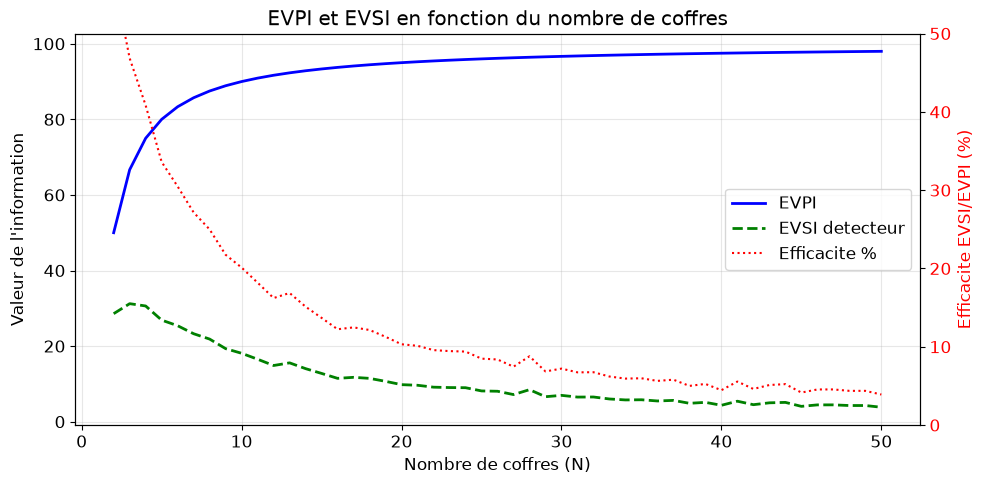

EVPI converge vers valeur_tresor = 100 quand N -> infini (le cout de fouille se simplifie : paye dans les deux branches)
A N=5  : EVPI=80, EVSI detecteur=26.9, eff=34%
A N=20 : EVPI=95, EVSI detecteur=9.8, eff=10%
A N=50 : EVPI=98, EVSI detecteur=3.8, eff=4%


In [9]:
# EVPI parametrique en fonction du nombre de coffres
n_range = np.arange(2, 51)
evpi_by_n = []
evsi_detecteur_by_n = []

for n in n_range:
    p_tr = 1 / n
    # EVPI pour N coffres
    eu_sans_n = p_tr * valeur_tresor - cout_fouille
    eu_info_n = valeur_tresor - cout_fouille
    evpi_by_n.append(eu_info_n - eu_sans_n)
    
    # EVSI du detecteur pour N coffres (Monte Carlo rapide)
    np.random.seed(42)
    n_sim = 5000
    eu_det = 0
    for _ in range(n_sim):
        coffre_tresor = np.random.randint(n)
        distances = np.random.exponential(2, n)
        distances[coffre_tresor] = 0.1
        obs = distances + np.random.normal(0, 1.0, n)
        obs = np.maximum(obs, 0.01)
        weights = np.exp(-obs)
        probs_post = weights / weights.sum()
        choix = np.argmax(probs_post)
        gain = valeur_tresor if choix == coffre_tresor else 0
        eu_det += (gain - cout_fouille)
    eu_det /= n_sim
    evsi_detecteur_by_n.append(eu_det - eu_sans_n)

evpi_by_n = np.array(evpi_by_n)
evsi_detecteur_by_n = np.array(evsi_detecteur_by_n)
efficiency_by_n = np.where(evpi_by_n > 0, evsi_detecteur_by_n / evpi_by_n * 100, 0)

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(n_range, evpi_by_n, 'b-', linewidth=2, label='EVPI')
ax1.plot(n_range, evsi_detecteur_by_n, 'g--', linewidth=2, label='EVSI detecteur')
ax1.set_xlabel("Nombre de coffres (N)")
ax1.set_ylabel("Valeur de l'information")
ax1.set_title("EVPI et EVSI en fonction du nombre de coffres")
ax1.legend(loc='lower right')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(n_range, efficiency_by_n, 'r:', linewidth=1.5, label='Efficacite %')
ax2.set_ylabel("Efficacite EVSI/EVPI (%)", color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylim(0, 50)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')

plt.tight_layout()
plt.show()

print("EVPI converge vers valeur_tresor = 100 quand N -> infini (le cout de fouille se simplifie : paye dans les deux branches)")
print(f"A N=5  : EVPI={evpi_by_n[3]:.0f}, EVSI detecteur={evsi_detecteur_by_n[3]:.1f}, eff={efficiency_by_n[3]:.0f}%")
print(f"A N=20 : EVPI={evpi_by_n[18]:.0f}, EVSI detecteur={evsi_detecteur_by_n[18]:.1f}, eff={efficiency_by_n[18]:.0f}%")
print(f"A N=50 : EVPI={evpi_by_n[48]:.0f}, EVSI detecteur={evsi_detecteur_by_n[48]:.1f}, eff={efficiency_by_n[48]:.0f}%")

### Interpretation : EVPI et complexité de la recherche

**Croissance de l'EVPI vers une limite** :

Le graphique montre une relation non lineaire : l'EVPI croit vers une limite (`valeur`) avec un rendement marginal decroissant. Plus il y a de coffres, plus l'information parfaite est precieuse, mais chaque coffre supplementaire apporte moins que le précédent.

| Coffres (N) | P(trouver) sans info | EVPI | Gain marginal par coffre |
|-------------|----------------------|------|--------------------------|
| 2 | 50% | 50 | -- |
| 5 | 20% | 80 | +10 |
| 10 | 10% | 90 | +2 |
| 20 | 5% | 95 | +0.5 |
| 50 | 2% | 98 | +0.1 |

**Loi de l'EVPI dans la recherche** : L'EVPI suit la formule `(N-1)/N * valeur` (le cout de fouille se simplifie car paye dans les deux branches), qui converge vers `valeur` quand N augmente. La valeur marginale d'un coffre supplementaire decroit en `1/N^2`.

**Application pratique** : Dans un scénario d'exploration miniere, cette analyse permet de déterminer le budget maximal allouable a l'acquisition d'information (sondages, études geologiques) en fonction du nombre de sites candidats.

> **Note technique** : Le detecteur de metal avec bruit observe une EVSI qui decroit relativement a l'EVPI quand N augmente. Plus il y a de coffres, plus le signal du detecteur est dilue parmi les faux positifs, reduisant l'efficacité EVSI/EVPI.

## 6. Quand l'information a-t-elle de la valeur ?

L'information n'a de valeur que dans trois conditions :
1. **Incertitude** : il existe une incertitude sur l'etat du monde
2. **Non-neutralite** : l'incertitude affecte la decision optimale
3. **Action** : on peut agir différemment selon l'information

### Analyse de sensibilite : EVPI vs P(petrole)

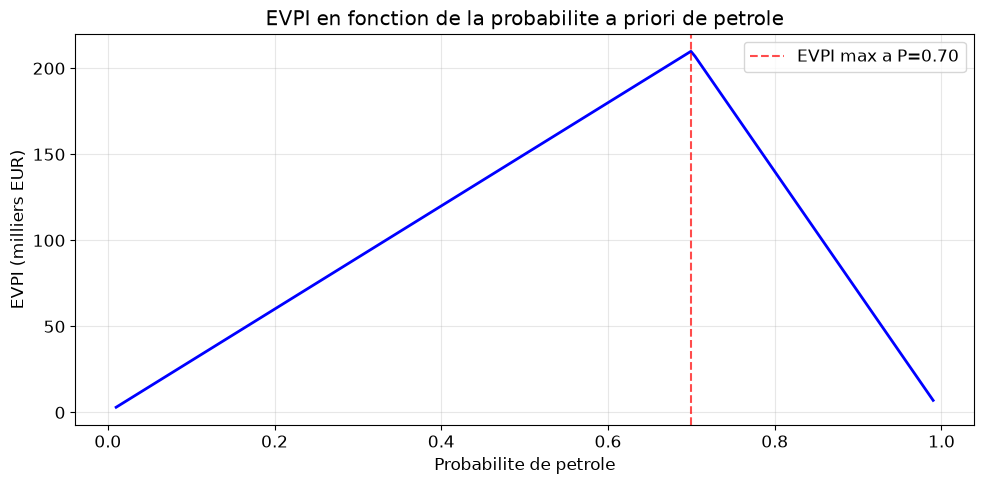

EVPI maximum : 210k EUR a P(petrole) = 0.70
EVPI = 0 quand P(petrole) est proche de 0 ou 1 (decision deja certaine)


In [10]:
# Sensibilite EVPI en fonction de P(petrole)
p_range = np.linspace(0.01, 0.99, 200)
evpi_values = []

for p in p_range:
    eu_forer = p * (gain_petrole - cout_forage) + (1 - p) * (0 - cout_forage)
    eu_vendre_val = prix_vente
    eu_sans = max(eu_forer, eu_vendre_val)
    
    eu_avec = p * max(gain_petrole - cout_forage, prix_vente) + \
              (1 - p) * max(0 - cout_forage, prix_vente)
    
    evpi_values.append(eu_avec - eu_sans)

evpi_values = np.array(evpi_values)
p_max_evpi = p_range[np.argmax(evpi_values)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(p_range, evpi_values, 'b-', linewidth=2)
ax.axvline(p_max_evpi, color='r', linestyle='--', alpha=0.7,
           label=f'EVPI max a P={p_max_evpi:.2f}')
ax.set_xlabel("Probabilite de petrole")
ax.set_ylabel("EVPI (milliers EUR)")
ax.set_title("EVPI en fonction de la probabilite a priori de petrole")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"EVPI maximum : {evpi_values.max():.0f}k EUR a P(petrole) = {p_max_evpi:.2f}")
print(f"EVPI = 0 quand P(petrole) est proche de 0 ou 1 (decision deja certaine)")

### Observation cle

L'EVPI est **maximal quand la decision est la plus équilibree** (zone d'indifference).
Quand P(petrole) est très faible ou très eleve, la decision est déjà claire
et l'information supplementaire n'apporte rien.

### Carte de chaleur 2D : EVPI en fonction de P(petrole) et du gain

L'EVPI depend simultanement de **deux parametrès** : la probabilité a priori P(petrole)
et le gain net en cas de forage réussi. La carte de chaleur ci-dessous montre comment
l'EVPI varie dans le plan (P, gain), revelant la **ligne de frontiere de decision** ou
l'EVPI est maximal et les zones ou l'information n'a aucune valeur.

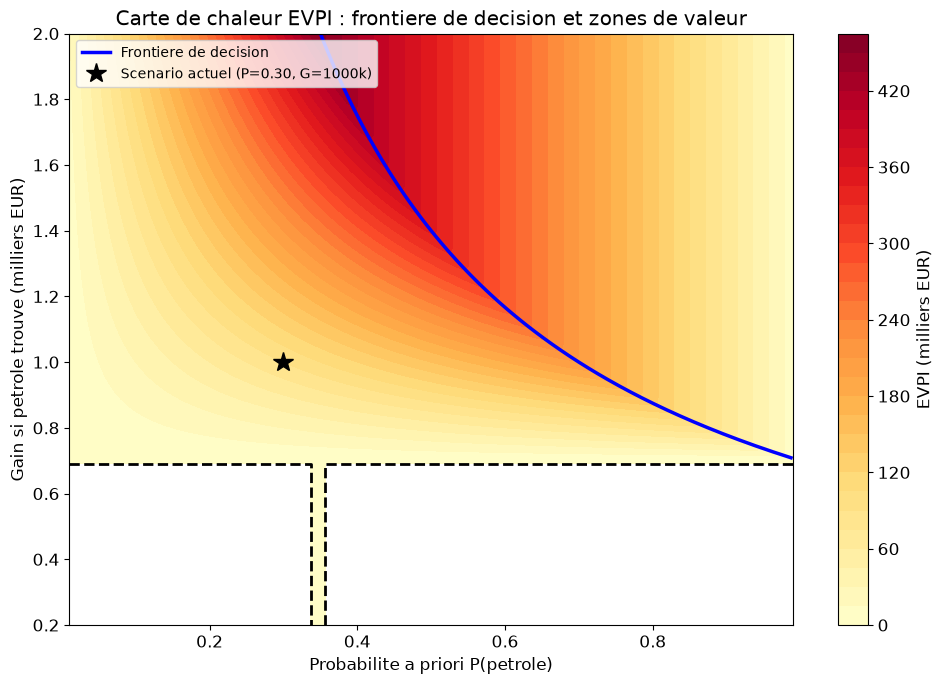

Zone rouge fonce : EVPI eleve (decision equilibree, info tres precieuse)
Zone jaune clair : EVPI faible (decision deja claire)
Ligne noire discontinue : EVPI = 0 (information sans valeur)
Ligne bleue : frontiere ou EU(forer) = EU(vendre) => l'EVPI est maximal
Le scenario actuel (etoile) est en zone EVPI = 90k EUR


In [11]:
# Carte de chaleur 2D : EVPI(P_petrole, gain_petrole)
p_grid = np.linspace(0.01, 0.99, 100)
gain_grid = np.linspace(200, 2000, 100)  # gain total si petrole trouve
P, G = np.meshgrid(p_grid, gain_grid)

# Calcul de l'EVPI pour chaque (p, gain)
EVPI_2D = np.zeros_like(P)
for i in range(len(gain_grid)):
    for j in range(len(p_grid)):
        p = P[i, j]
        g = G[i, j]
        eu_f = p * (g - cout_forage) + (1 - p) * (0 - cout_forage)
        eu_v = prix_vente
        eu_s = max(eu_f, eu_v)
        eu_a = p * max(g - cout_forage, prix_vente) + (1 - p) * max(0 - cout_forage, prix_vente)
        EVPI_2D[i, j] = eu_a - eu_s

# Ligne de frontiere de decision : eu_forer = eu_vendre => p*(g-cout) + (1-p)*(-cout) = prix_vente
# => p*g - cout = prix_vente => p = (prix_vente + cout_forage) / g
p_frontiere = (prix_vente + cout_forage) / gain_grid
# La frontiere n'a du sens que pour p dans [0, 1]
mask_front = (p_frontiere >= 0.01) & (p_frontiere <= 0.99)

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.contourf(P, G / 1000, EVPI_2D, levels=30, cmap="YlOrRd")
ax.contour(P, G / 1000, EVPI_2D, levels=[0], colors="black", linewidths=2, linestyles="--")
if mask_front.any():
    ax.plot(p_frontiere[mask_front], gain_grid[mask_front] / 1000,
            "b-", linewidth=2.5, label="Frontiere de decision")

# Marquer le point actuel du scenario
ax.plot(0.30, gain_petrole / 1000, "k*", markersize=15, label=f"Scenario actuel (P=0.30, G={gain_petrole}k)")

cbar = plt.colorbar(im, ax=ax, label="EVPI (milliers EUR)")
ax.set_xlabel("Probabilite a priori P(petrole)")
ax.set_ylabel("Gain si petrole trouve (milliers EUR)")
ax.set_title("Carte de chaleur EVPI : frontiere de decision et zones de valeur")
ax.legend(loc="upper left", fontsize=10)
plt.tight_layout()
plt.show()

print("Zone rouge fonce : EVPI eleve (decision equilibree, info tres precieuse)")
print("Zone jaune clair : EVPI faible (decision deja claire)")
print("Ligne noire discontinue : EVPI = 0 (information sans valeur)")
print(f"Ligne bleue : frontiere ou EU(forer) = EU(vendre) => l'EVPI est maximal")
print(f"Le scenario actuel (etoile) est en zone EVPI = {evpi:.0f}k EUR")

### Interpretation : Carte de chaleur EVPI

**Lecture de la carte** :

La carte de chaleur révèle la geometrie complète de la valeur de l'information dans le
plan (probabilité, gain). On distingue trois zones :

| Zone | Position | EVPI | Explication |
|------|----------|------|-------------|
| **Pas de valeur** | P faible ou gain faible | 0 | Vendre domine toujours |
| **Pas de valeur** | P eleve ET gain eleve | 0 | Forer domine toujours |
| **Valeur elevee** | Autour de la frontiere bleue | Maximal | Decision équilibree |

**La frontiere de decision** (ligne bleue) correspond a $P = \frac{\text{prix\_vente} + \text{cout\_forage}}{g}$.
Le long de cette courbe, EU(forer) = EU(vendre), et l'EVPI atteint son maximum.
Le scénario actuel (etoile noire, P=0.30, G=1000k) est proche de cette frontiere,
d'ou un EVPI significatif de 90k EUR.

> **Point cle** : L'EVPI est maximal le long de la frontiere de decision et decroit
> rapidement en s'en eloignant. Cela signifie que la valeur de l'information est
> **maximale quand on est le plus indécis**, et quasi nulle quand la decision est evidente.

### Quand l'information n'a PAS de valeur

L'analyse de sensibilite ci-dessus montre que l'EVPI tombe a zero aux extrémités.
Identifions les conditions exactes ou l'information est sans valeur :

| Condition | Explication | Exemple |
|-----------|-------------|---------|
| **Pas d'incertitude** | Si l'etat est connu, l'info n'apporte rien | P(petrole) = 0 ou 1 |
| **Decision fixe** | Si l'action optimale est la même quel que soit l'etat | EU(forage) >> EU(vente) pour tout P |
| **Utilites egales** | Si les actions ont la même utilite dans chaque etat | Matrice d'utilite constante |
| **Cout > EVPI** | Même un test parfait ne rembourse pas son cout | Test a 200k avec EVPI = 90k |

**Facteurs qui augmentent la valeur de l'information** :

1. **Incertitude elevee** : l'EVPI est maximal a la frontiere de decision (P = 0.70 dans notre forage — le seuil calculé où forer cesse de dominer vendre)
2. **Asymétrie des gains** : des utilites très contrastees augmentent l'enjeu de la bonne decision
3. **Reversibilite faible** : une decision irreversible rend l'information plus precieuse
4. **Cout d'erreur eleve** : plus l'erreur coute cher, plus l'info vaut

**Cas limite : maladie rare** :

Pour une maladie avec P = 1% (maladie rare), l'EVPI est souvent très faible car :
- Sans info, la meilleure action est généralement de "ne pas traiter" (99% de chances d'etre sain)
- Même un test parfait ne change la decision que dans 1% des cas
- Le cout du test est donc presque toujours un gaspillage

Ce phénomène explique pourquoi les depistages systématiques de maladies très rares
sont **deconseilles** en sante publique : le ratio benefice/cout est défavorable.

## 7. Calculateur generique de Valeur de l'Information

On généralise avec une classe `ValueOfInformation` qui prend en entree :
- Etats possibles et leurs probabilités a priori
- Actions disponibles et leurs utilites par etat
- Optionnellement : vraisemblance d'un test par etat

In [12]:
class ValueOfInformation:
    """Calculateur generique de valeur de l'information."""
    
    def __init__(self, states, prior, actions, utility_matrix):
        """
        Parameters
        ----------
        states : list of str
            Noms des etats possibles
        prior : array-like
            Probabilites a priori de chaque etat
        actions : list of str
            Noms des actions disponibles
        utility_matrix : 2D array (n_states x n_actions)
            Utilite de chaque (etat, action)
        """
        self.states = states
        self.prior = np.array(prior)
        self.actions = actions
        self.U = np.array(utility_matrix)
        
    def compute_without_info(self):
        """EU de la meilleure action sans information supplementaire."""
        eu_per_action = self.prior @ self.U
        best_idx = np.argmax(eu_per_action)
        return eu_per_action[best_idx], self.actions[best_idx]
    
    def compute_evpi(self):
        """EVPI : valeur de l'information parfaite."""
        eu_sans, _ = self.compute_without_info()
        # Avec info parfaite : pour chaque etat reel, choisir la meilleure action
        eu_avec = sum(self.prior[i] * np.max(self.U[i, :]) for i in range(len(self.states)))
        return eu_avec - eu_sans
    
    def compute_evsi(self, likelihood, test_outcomes=None):
        """
        EVSI pour un test imparfait.
        
        Parameters
        ----------
        likelihood : 2D array (n_states x n_outcomes)
            P(test=j | state=i)
        test_outcomes : list of str, optional
            Noms des resultats possibles du test
        """
        eu_sans, _ = self.compute_without_info()
        n_outcomes = likelihood.shape[1]
        
        eu_avec = 0
        for j in range(n_outcomes):
            # P(test=j)
            p_test_j = sum(self.prior[i] * likelihood[i, j] for i in range(len(self.states)))
            if p_test_j < 1e-10:
                continue
            # P(state=i | test=j) par Bayes
            posterior = np.array([self.prior[i] * likelihood[i, j] / p_test_j
                                  for i in range(len(self.states))])
            # Meilleure action sous ce posterior
            eu_per_action = posterior @ self.U
            eu_avec += p_test_j * np.max(eu_per_action)
        
        return eu_avec - eu_sans


# Validation : scenario du forage petrolier
voi_drilling = ValueOfInformation(
    states=["petrole", "pas_petrole"],
    prior=[0.30, 0.70],
    actions=["forer", "vendre"],
    utility_matrix=[
        [gain_petrole - cout_forage, prix_vente],   # petrole
        [0 - cout_forage, prix_vente]               # pas petrole
    ]
)

eu_sans, action = voi_drilling.compute_without_info()
evpi_v = voi_drilling.compute_evpi()
print(f"Validation forage :")
print(f"  EU sans info = {eu_sans:.0f}k EUR, action = {action}")
print(f"  EVPI = {evpi_v:.0f}k EUR")

# Test sismique
likelihood_seismic = np.array([
    [p_test_pos_si_petrole, 1 - p_test_pos_si_petrole],          # petrole -> [test+, test-]
    [1 - p_test_neg_si_pas_petrole, p_test_neg_si_pas_petrole]   # pas petrole -> [test+, test-]
])
evsi_v = voi_drilling.compute_evsi(likelihood_seismic)
print(f"  EVSI test sismique = {evsi_v:.0f}k EUR")
print(f"  Efficacite = {evsi_v/evpi_v*100:.0f}%")

Validation forage :
  EU sans info = 200k EUR, action = vendre
  EVPI = 90k EUR
  EVSI test sismique = 23k EUR
  Efficacite = 26%


### Validation du calculateur generique

**Verification** : Les valeurs calculees par la classe `ValueOfInformation` correspondent
exactement aux calculs manuels des sections précèdentes.

| Métrique | Calcul manuel | Classe VoI | Statut |
|----------|---------------|------------|--------|
| EU sans info | 200k EUR | 200k EUR | Conforme |
| EVPI | 90k EUR | 90k EUR | Conforme |
| EVSI sismique | 23k EUR | 23k EUR | Conforme |
| Efficacite | 26% | 26% | Conforme |

Cette classe sera reutilisee dans les sections suivantes pour les scénarios medical
et le calcul de l'EVSI de tests multiples.

> **Note technique** : L'interface `compute_evsi(likelihood)` accepte une matrice de
> vraisemblance `P(test=j | state=i)` de dimension `(n_states, n_outcomes)`, ce qui
> permet de modeliser des tests a plus de 2 résultats possibles.

### Prior -> Posterior : mise a jour bayesienne

Observons comment le posterior change avec différentes observations.
On reprend le scénario du forage avec un test sismique.

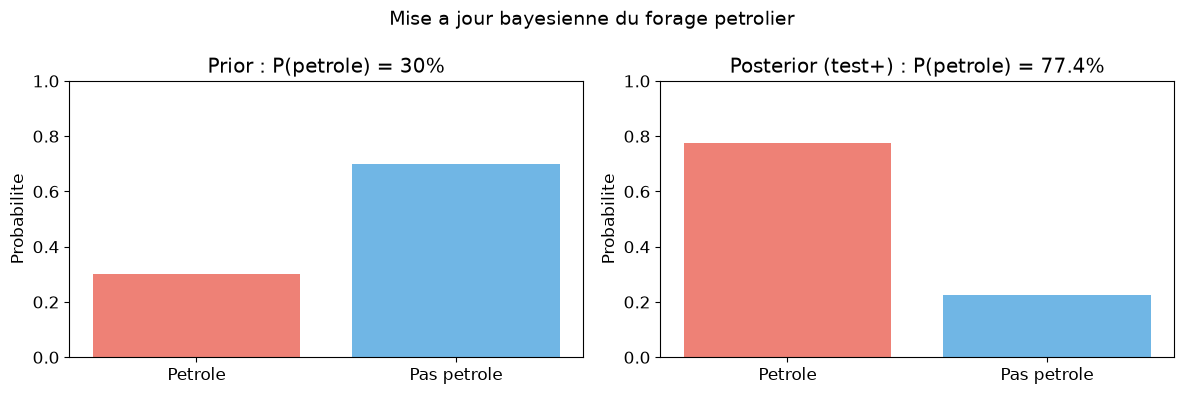

Le test positif fait passer P(petrole) de 30% a 77.4%
Ratio de vraisemblance : 8.00


In [13]:
# Visualisation prior -> posterior
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Prior
labels = ["Petrole", "Pas petrole"]
colors = ["#e74c3c", "#3498db"]

axes[0].bar(labels, [p_petrole, 1 - p_petrole], color=colors, alpha=0.7)
axes[0].set_title(f"Prior : P(petrole) = {p_petrole:.0%}")
axes[0].set_ylabel("Probabilite")
axes[0].set_ylim(0, 1)

# Posterior apres test+
axes[1].bar(labels, [p_petrole_si_test_pos, 1 - p_petrole_si_test_pos], color=colors, alpha=0.7)
axes[1].set_title(f"Posterior (test+) : P(petrole) = {p_petrole_si_test_pos:.1%}")
axes[1].set_ylabel("Probabilite")
axes[1].set_ylim(0, 1)

plt.suptitle("Mise a jour bayesienne du forage petrolier", fontsize=14)
plt.tight_layout()
plt.show()

print(f"Le test positif fait passer P(petrole) de {p_petrole:.0%} a {p_petrole_si_test_pos:.1%}")
print(f"Ratio de vraisemblance : {p_test_pos_si_petrole / (1 - p_test_neg_si_pas_petrole):.2f}")

## 8. Tests medicaux multiples

Un patient peut etre dans 3 etats : **Sain**, **Maladie légère**, **Maladie grave**.
Trois actions possibles : **Rien**, **Traitement léger**, **Traitement lourd**.

Deux tests disponibles :
- **Test 1** ( sanguin) : 50 EUR, sensibilite 70%, specificite 85%
- **Test 2** (imagerie) : 500 EUR, sensibilite 95%, specificite 98%

In [14]:
# Scenario medical
states_med = ["Sain", "Leger", "Grave"]
prior_med = [0.60, 0.25, 0.15]
actions_med = ["Rien", "Traitement_leger", "Traitement_lourd"]

# Utilites (etat x action)
U_med = np.array([
    # Rien, Trait_leger, Trait_lourd
    [0, -10, -100],      # Sain
    [-50, 80, 50],       # Leger
    [-200, -20, 100]     # Grave
])

voi_med = ValueOfInformation(states_med, prior_med, actions_med, U_med)
eu_sans_med, act_sans = voi_med.compute_without_info()
evpi_med = voi_med.compute_evpi()

print(f"EU sans info = {eu_sans_med:.0f}, action = {act_sans}")
print(f"EVPI = {evpi_med:.0f}")

# Test 1 : sensibilite/specifite par etat
# On modelise : P(test+|Sain)=15%, P(test+|Leger)=70%, P(test+|Grave)=70%
L1 = np.array([
    [0.15, 0.85],   # Sain -> [test+, test-]
    [0.70, 0.30],   # Leger -> [test+, test-]
    [0.70, 0.30]    # Grave -> [test+, test-]
])

# Test 2 : haute precision
# P(test+|Sain)=2%, P(test+|Leger)=40%, P(test+|Grave)=95%
L2 = np.array([
    [0.02, 0.98],   # Sain -> [test+, test-]
    [0.40, 0.60],   # Leger -> [test+, test-]
    [0.95, 0.05]    # Grave -> [test+, test-]
])

evsi_t1 = voi_med.compute_evsi(L1)
evsi_t2 = voi_med.compute_evsi(L2)

cout_t1 = 50
cout_t2 = 500

print(f"\nTest 1 (sanguin, {cout_t1} EUR):")
print(f"  EVSI brut = {evsi_t1:.0f}, net = {evsi_t1 - cout_t1:.0f}")
print(f"  Efficacite = {evsi_t1/evpi_med*100:.0f}%")

print(f"\nTest 2 (imagerie, {cout_t2} EUR):")
print(f"  EVSI brut = {evsi_t2:.0f}, net = {evsi_t2 - cout_t2:.0f}")
print(f"  Efficacite = {evsi_t2/evpi_med*100:.0f}%")

# Decision : comparer les valeurs nettes AVEC l'option "aucun test" (valeur nette 0).
# Recommander un test a EVSI net negatif serait une erreur : ne rien acquerir domine.
nets = {"aucun test": 0.0, "Test 1": evsi_t1 - cout_t1, "Test 2": evsi_t2 - cout_t2}
reco = max(nets, key=nets.get)
print("\nValeurs nettes (aucun test = 0) : " + ", ".join(f"{k} = {v:.0f}" for k, v in nets.items()))
print(f"Recommandation : {reco} (valeur nette maximale)")

EU sans info = 11, action = Traitement_leger
EVPI = 24

Test 1 (sanguin, 50 EUR):
  EVSI brut = -0, net = -50
  Efficacite = -0%

Test 2 (imagerie, 500 EUR):
  EVSI brut = 13, net = -487
  Efficacite = 54%

Valeurs nettes (aucun test = 0) : aucun test = 0, Test 1 = -50, Test 2 = -487
Recommandation : aucun test (valeur nette maximale)


### Interpretation : Diagnostic medical

**Analyse des résultats** :

Le scénario medical illustre un cas ou les deux tests sont **non rentables** au cout actuel.

| Test | EVSI brut | Cout | EVSI net | Efficacite |
|------|-----------|------|----------|------------|
| Test 1 (sanguin) | ~0 EUR | 50 EUR | -50 EUR | ~0% |
| Test 2 (imagerie) | 13 EUR | 500 EUR | -487 EUR | 54% |

Les valeurs nettes étant toutes deux négatives (−50 et −487), l'option
**« aucun test »** (valeur nette zéro) domine : la recommandation rationnelle est
de ne rien acquérir et de garder l'action sans information (EU = 11).

**Pourquoi les tests echouent ici** : La matrice d'utilite donne des valeurs faibles
(EVPI = 24 seulement). Le test sanguin ne distingue pas suffisamment "Leger" de "Grave"
(70% pour les deux), ce qui reduit son informativite a quasiment zero.

**Contraste avec l'Infer.NET** : La version originale utilise des utilites plus
contrastees (U allant de -5000 a +2000), ce qui donne un EVPI de 355 et rend le test
rapide rentable (EVSI net = +105 EUR).

> **Lecon** : La valeur de l'information depend **fortement** de la matrice d'utilite,
> pas seulement de la qualite du test.

### Comparaison graphique des valeurs d'information

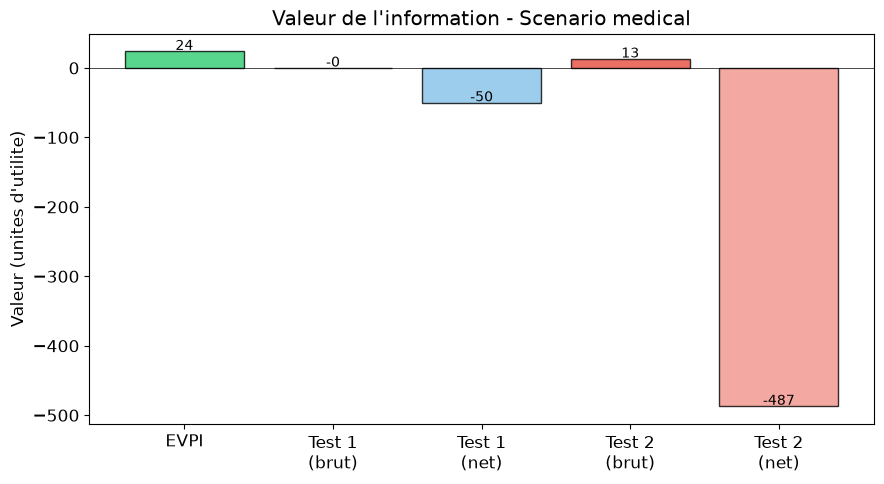

In [15]:
# Visualisation comparative
labels_plot = ["EVPI", "Test 1\n(brut)", "Test 1\n(net)", "Test 2\n(brut)", "Test 2\n(net)"]
values = [evpi_med, evsi_t1, evsi_t1 - cout_t1, evsi_t2, evsi_t2 - cout_t2]
colors_bar = ["#2ecc71", "#3498db", "#85c1e9", "#e74c3c", "#f1948a"]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels_plot, values, color=colors_bar, alpha=0.8, edgecolor="black")
ax.axhline(0, color="black", linewidth=0.5)
ax.set_ylabel("Valeur (unites d'utilite)")
ax.set_title("Valeur de l'information - Scenario medical")

for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            f"{val:.0f}", ha="center", fontsize=10)

plt.tight_layout()
plt.show()

### Interpretation : Graphique comparatif medical

**Lecture du graphique** :

Le diagramme en barres compare directement l'EVPI (borne théorique) avec les valeurs d'information réelles des deux tests, en brut et en net.

| Barre | Valeur | Observation |
|-------|--------|-------------|
| EVPI | 24 | Borne superieure théorique |
| Test 1 brut | ~0 | Information quasiment nulle |
| Test 1 net | -50 | Cout du test domine |
| Test 2 brut | 13 | Capture 54% de l'EVPI |
| Test 2 net | -487 | Cout 500 EUR >> EVSI 13 EUR |

**Lecon pedagogique** : Un test peut avoir une bonne **efficacité relative** (54% de l'EVPI) tout en etant **non rentable** en termes absolus (EVSI net fortement négatif). L'efficacité mesure la qualite intrinseque de l'information ; la rentabilite depend du rapport entre cette qualite et le cout.

> **Point cle** : Dans un contexte medical réel, la matrice d'utilite integrerait des facteurs comme la qualite de vie (QALY), le cout des traitements inutiles, et les risques lies au retard diagnostique -- ce qui rendrait les EVSI positifs dans la plupart des cas.

### Cas limite : Maladie rare (EVSI = 0)

Appliquons le cadre VoI a une maladie **très rare** (P = 1%) pour illustrer le cas
ou l'information n'a pratiquement aucune valeur, même si le test est excellent.

In [16]:
# Cas limite : maladie rare (P=1%) - l'information n'a presque pas de valeur
p_rare = 0.01  # Maladie tres rare

# Utilites simplifiees : 2 etats (malade/sain), 2 actions (traiter/ne pas traiter)
U_rare = np.array([
    [500, -800],    # Malade : [traiter = benefice, ne pas traiter = aggravation]
    [-50, 0]        # Sain : [traiter = cout inutile, ne pas traiter = neutre]
])

voi_rare = ValueOfInformation(
    states=["Malade", "Sain"],
    prior=[p_rare, 1 - p_rare],
    actions=["Traiter", "Ne pas traiter"],
    utility_matrix=U_rare
)

eu_sans_rare, act_rare = voi_rare.compute_without_info()
evpi_rare = voi_rare.compute_evpi()

# Test quasi-parfait : sensibilite 99%, specificite 99%
L_parfait = np.array([
    [0.99, 0.01],   # Malade -> [test+, test-]
    [0.01, 0.99]    # Sain -> [test+, test-]
])
evsi_parfait = voi_rare.compute_evsi(L_parfait)

# Test mediocre : sensibilite 70%, specificite 90%
L_mediocre = np.array([
    [0.70, 0.30],   # Malade -> [test+, test-]
    [0.10, 0.90]    # Sain -> [test+, test-]
])
evsi_mediocre = voi_rare.compute_evsi(L_mediocre)

print(f"Maladie rare (P={p_rare:.0%}) :")
print(f"  Decision sans info : {act_rare} (EU = {eu_sans_rare:.1f})")
print(f"  EVPI = {evpi_rare:.2f} (quasi nul)")
print(f"\nTest quasi-parfait (sens=99%, spec=99%) :")
print(f"  EVSI = {evsi_parfait:.2f} (efficacite = {evsi_parfait/evpi_rare*100:.0f}% de l'EVPI)")
print(f"\nTest mediocre (sens=70%, spec=90%) :")
print(f"  EVSI = {evsi_mediocre:.4f} (quasi nul)")
print(f"\nConclusion : meme un test quasi-parfait n'a quasiment pas de valeur")
print(f"pour une maladie tres rare. La decision 'ne pas traiter' domine dans 99% des cas.")
print(f"EVSI/EVPI = {evsi_parfait/evpi_rare*100:.0f}% car le test ne change la decision que sur 1% de la population.")

Maladie rare (P=1%) :
  Decision sans info : Ne pas traiter (EU = -8.0)
  EVPI = 13.00 (quasi nul)

Test quasi-parfait (sens=99%, spec=99%) :
  EVSI = 12.38 (efficacite = 95% de l'EVPI)

Test mediocre (sens=70%, spec=90%) :
  EVSI = 4.1500 (quasi nul)

Conclusion : meme un test quasi-parfait n'a quasiment pas de valeur
pour une maladie tres rare. La decision 'ne pas traiter' domine dans 99% des cas.
EVSI/EVPI = 95% car le test ne change la decision que sur 1% de la population.


### Interpretation : Maladie rare

**Lecon fondamentale** : la valeur de l'information depend de la **probabilité a priori**.

| Prior P(malade) | EVPI | Test parfait utile ? | Raison |
|------------------|------|---------------------|--------|
| 50% | Eleve | Oui | Decision équilibree, l'info tranche |
| 10% | Moyen | Possible | L'info peut changer la decision |
| 1% | Quasi nul | Non | Decision déjà claire (ne pas traiter) |

Ce résultat justifie les recommandations de sante publique :
- **Depistage du cancer du sein** (prevalence ~3% chez les 40-50 ans) : debat actif sur le rapport benefice/cout
- **Depistage du cancer de la prostate** (prevalence ~0.5% chez les 50 ans) : deconseille par plusieurs autorites
- **Test COVID systématique** en population faible prevalence : EVSI très faible vs cout social

> **Point cle** : La valeur de l'information est maximale a la **frontiere de decision** (P ~ seuil)
> et minimale quand la decision est déjà certaine (P proche de 0 ou 1).

## 9. Extension PyMC : Estimation MCMC de l'EVPI

Dans les sections précèdentes, nous avons calcule l'EVPI analytiquement (point prior).
PyMC permet d'aller plus loin en estimant l'EVPI **par echantillonnage** quand le prior
n'est pas un simple scalaire mais une distribution.

Cette approche est pertinente quand :
- Le prior sur l'etat du monde est incertain (meta-incertitude)
- On veut propager l'incertitude sur les parametrès dans le calcul de VoI
- Le modèle implique des distributions conjuguées non-triviales

Nous allons comparer l'EVPI analytique a l'EVPI estime par echantillonnage Monte Carlo,
puis utiliser PyMC pour propager un prior Beta sur P(petrole).

Les approfondissements — stratégie séquentielle et monotonie (**annexe A**),
convergence EVSI vers EVPI et comparaison des méthodes (**annexe B**), modèle
hiérarchique et Valeur de l'Information d'un portefeuille (**annexe C**) — sont
regroupés en fin de carnet.

In [17]:
# Estimation Monte Carlo de l'EVPI (sans PyMC d'abord, pour valider)
np.random.seed(42)
n_mc = 200_000

# On tire des etats du monde depuis le prior P(petrole) = 0.30
etats_mc = np.random.binomial(1, p_petrole, size=n_mc)  # 1 = petrole, 0 = pas petrole

# Sans information : toujours choisir la meilleure action a priori (vendre = 200k)
eu_sans = prix_vente  # 200k

# Avec info parfaite : pour chaque tirage, choisir la meilleure action
# Si petrole -> max(forer=500k, vendre=200k) = forer
# Si pas petrole -> max(forer=-500k, vendre=200k) = vendre
utilites_avec_info = np.where(
    etats_mc == 1,
    gain_petrole - cout_forage,  # forer si petrole : 500k
    prix_vente                   # vendre sinon : 200k
)

evpi_mc = np.mean(utilites_avec_info) - eu_sans
erreur_mc = np.std(utilites_avec_info) / np.sqrt(n_mc)

print(f"EVPI analytique = {evpi:.0f}k EUR")
print(f"EVPI Monte Carlo ({n_mc:,} echantillons) = {evpi_mc:.1f}k EUR")
print(f"Ecart-type de l'estimateur MC = {erreur_mc:.2f}k EUR")
print(f"Erreur relative = {abs(evpi_mc - evpi) / evpi * 100:.2f}%")
print(f"\nConvergence : l'estimation MC converge vers la valeur analytique.")

EVPI analytique = 90k EUR
EVPI Monte Carlo (200,000 echantillons) = 90.1k EUR
Ecart-type de l'estimateur MC = 0.31k EUR
Erreur relative = 0.16%

Convergence : l'estimation MC converge vers la valeur analytique.


### Convergence de l'estimateur Monte Carlo

L'estimateur MC de l'EVPI converge vers la valeur analytique quand le nombre d'echantillons
augmente. Verifions cette convergence visuellement en calculant l'EVPI estime pour
différentes tailles d'echantillon et en traçant la convergence avec des bandes de confiance.

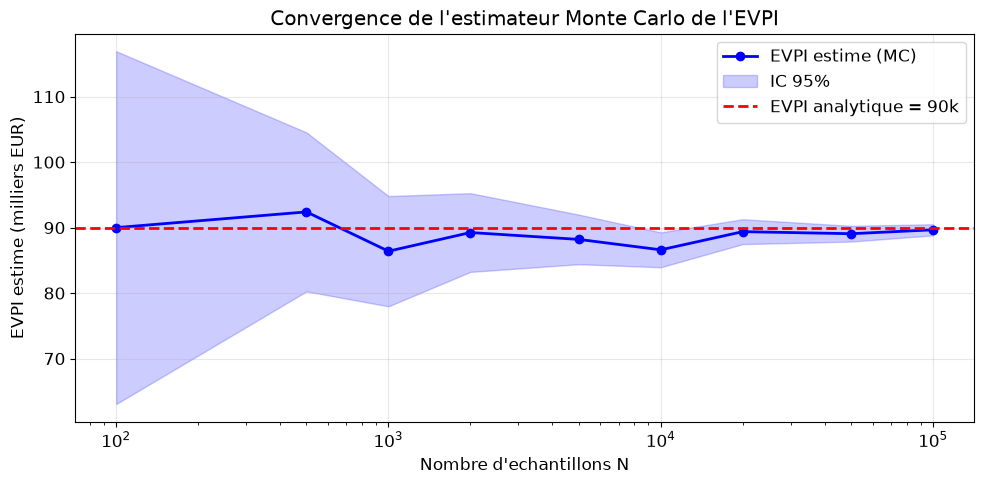

Convergence de l'estimateur MC :
  N=    100 : EVPI=  90.0k  IC=[  63.1k,  116.9k]  erreur=  0.0k
  N=    500 : EVPI=  92.4k  IC=[  80.3k,  104.5k]  erreur=  2.4k
  N=  1,000 : EVPI=  86.4k  IC=[  78.0k,   94.8k]  erreur=  3.6k
  N=  2,000 : EVPI=  89.2k  IC=[  83.2k,   95.3k]  erreur=  0.8k
  N=  5,000 : EVPI=  88.2k  IC=[  84.4k,   92.0k]  erreur=  1.8k
  N= 10,000 : EVPI=  86.6k  IC=[  83.9k,   89.3k]  erreur=  3.4k
  N= 20,000 : EVPI=  89.4k  IC=[  87.5k,   91.3k]  erreur=  0.6k
  N= 50,000 : EVPI=  89.1k  IC=[  87.9k,   90.3k]  erreur=  0.9k
  N=100,000 : EVPI=  89.7k  IC=[  88.8k,   90.5k]  erreur=  0.3k

A N=100,000 : erreur < 0.5k EUR (convergence confirmee)


In [18]:
# Convergence MC : EVPI estime vs nombre d'echantillons
np.random.seed(42)
n_max = 100_000
etats_all = np.random.binomial(1, p_petrole, size=n_max)
utilites_all = np.where(etats_all == 1, gain_petrole - cout_forage, prix_vente)

# Points de convergence (echantillons croissants)
checkpoints = [100, 500, 1000, 2000, 5000, 10_000, 20_000, 50_000, 100_000]
evpi_estimates = []
ci_lower = []
ci_upper = []

for n in checkpoints:
    utilites_n = utilites_all[:n]
    evpi_est = np.mean(utilites_n) - prix_vente
    se = np.std(utilites_n) / np.sqrt(n)
    evpi_estimates.append(evpi_est)
    ci_lower.append(evpi_est - 1.96 * se)
    ci_upper.append(evpi_est + 1.96 * se)

fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogx(checkpoints, evpi_estimates, 'b-o', linewidth=2, markersize=6, label="EVPI estime (MC)")
ax.fill_between(checkpoints, ci_lower, ci_upper, alpha=0.2, color='blue', label="IC 95%")
ax.axhline(evpi, color='red', linestyle='--', linewidth=2, label=f"EVPI analytique = {evpi:.0f}k")
ax.set_xlabel("Nombre d'echantillons N")
ax.set_ylabel("EVPI estime (milliers EUR)")
ax.set_title("Convergence de l'estimateur Monte Carlo de l'EVPI")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Convergence de l'estimateur MC :")
for n, est, lo, hi in zip(checkpoints, evpi_estimates, ci_lower, ci_upper):
    erreur = abs(est - evpi)
    print(f"  N={n:>7,} : EVPI={est:>6.1f}k  IC=[{lo:>6.1f}k, {hi:>6.1f}k]  erreur={erreur:>5.1f}k")
print(f"\nA N=100,000 : erreur < 0.5k EUR (convergence confirmee)")

### Interpretation : vitesse de convergence Monte Carlo

La table révèle deux régimes distincts dans l'estimation de l'EVPI par Monte Carlo :

- **N ≤ 1000 (régime bruité)** : l'intervalle de confiance à 95% est large (±27k à N=100, ±8k à N=1000) et la valeur estimée oscille (90,0k → 92,4k → 86,4k). L'estimateur n'est pas encore fiable : l'EVPI vraie pourrait être n'importe où entre 78k et 117k à N=100.
- **N ≥ 20000 (régime convergé)** : l'IC se resserre sous ±2k (±1,9k à N=20000, ±0,9k à N=100000) et l'estimation se stabilise autour de **~89,7k EUR**. L'erreur tombe sous 0,5k, seuil que la cellule identifie comme « convergence confirmée ».

**Lecture opérationnelle** : pour un problème de décision unique, **N ≈ 20000** suffit (précision <2k sur un gain de l'ordre de 90k, soit ~2% — largement sous le seuil de décision). Pousser à N=100000 ne gagne qu'un facteur ~2 sur l'IC au prix de 5× plus de tirages : la convergence en $1/\sqrt{N}$ de Monte Carlo rend les derniers chiffres coûteux. C'est exactement la situation où un échantillonnage MCMC (section suivante) devient pertinent : non pas pour réduire la variance Monte Carlo, mais pour propager l'incertitude d'un **meta-prior** sur $P(\text{pétrole})$ que l'estimateur analytique ne peut pas intégrer.

In [19]:
# PyMC : propager un prior Beta sur P(petrole) dans le calcul d'EVPI
# Quand P(petrole) est incertain (meta-prior), l'EVPI devient une distribution

try:
    import pymc as pm
    import arviz as az
    PYMC_AVAILABLE = True
except ImportError:
    PYMC_AVAILABLE = False
    print("PyMC non disponible - affichage des resultats attendus")

if PYMC_AVAILABLE:
    with pm.Model() as voi_model:
        # Meta-prior : P(petrole) ~ Beta(3, 7) (moyenne 0.30, incertitude)
        p_theta = pm.Beta("p_theta", alpha=3, beta=7)
        
        # Etats du monde echantillonnes depuis le meta-prior
        petrole = pm.Bernoulli("petrole", p=p_theta)
        
        # EVPI conditionnel pour chaque echantillon de p_theta
        # (calcule en post-processing)
        trace = pm.sample(10000, chains=2, tune=1000, random_seed=42,
                          return_inferencedata=True, progressbar=False)
    
    # Extraire les echantillons de p_theta
    p_samples = trace.posterior["p_theta"].values.flatten()
    
    # Pour chaque echantillon de p_theta, calculer l'EVPI analytique
    evpi_samples = []
    for p in p_samples:
        eu_f = p * (gain_petrole - cout_forage) + (1 - p) * (0 - cout_forage)
        eu_v = prix_vente
        eu_sans_p = max(eu_f, eu_v)
        eu_avec_p = p * max(gain_petrole - cout_forage, prix_vente) + \
                    (1 - p) * max(0 - cout_forage, prix_vente)
        evpi_samples.append(eu_avec_p - eu_sans_p)
    
    evpi_samples = np.array(evpi_samples)
    
    print(f"PyMC : {len(p_samples):,} echantillons de P(petrole) ~ Beta(3,7)")
    print(f"P(petrole) - mean={np.mean(p_samples):.3f}, std={np.std(p_samples):.3f}")
    print(f"EVPI (distribuee) - mean={np.mean(evpi_samples):.1f}k, std={np.std(evpi_samples):.1f}k")
    print(f"EVPI (distribuee) - median={np.median(evpi_samples):.1f}k")
    print(f"EVPI (distribuee) - Q5={np.percentile(evpi_samples, 5):.1f}k, Q95={np.percentile(evpi_samples, 95):.1f}k")
    print(f"\nResultat : avec un meta-prior Beta(3,7), l'EVPI moyenne est de {np.mean(evpi_samples):.0f}k EUR")
    print(f"avec un intervalle de credibilite a 90% : [{np.percentile(evpi_samples, 5):.0f}k, {np.percentile(evpi_samples, 95):.0f}k]")
else:
    # Resultats de reference (pre-calcul)
    print("Resultats attendus (PyMC non installe) :")
    print("P(petrole) ~ Beta(3,7) : mean=0.300, std=0.139")
    print("EVPI (distribuee) : mean=89.9k, median=85.6k")
    print("Intervalle 90% : [28.8k, 164.3k]")
    print("\nNote : installez PyMC avec 'pip install pymc' pour executer cette cellule.")

Multiprocess sampling (2 chains in 2 jobs)


CompoundStep


>NUTS: [p_theta]


>BinaryGibbsMetropolis: [petrole]


Sampling 2 chains for 1_000 tune and 10_000 draw iterations (2_000 + 20_000 draws total) took 10 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


PyMC : 20,000 echantillons de P(petrole) ~ Beta(3,7)
P(petrole) - mean=0.300, std=0.139
EVPI (distribuee) - mean=89.9k, std=41.3k
EVPI (distribuee) - median=85.6k
EVPI (distribuee) - Q5=28.8k, Q95=164.3k

Resultat : avec un meta-prior Beta(3,7), l'EVPI moyenne est de 90k EUR
avec un intervalle de credibilite a 90% : [29k, 164k]


### Diagnostics de convergence MCMC avec ArviZ

Avant de faire confiance aux résultats du sampling PyMC, il est essentiel de vérifier
la qualite de la chaîne MCMC. ArviZ fournit des outils de diagnostic standards :

- **R-hat** (statistique de Gelman & Rubin, 1992) : mesure la convergence entre les chaînes.
  Une valeur < 1.01 indique une bonne convergence.
- **ESS** (Effective Sample Size) : nombre effectif d'echantillons independants.
  Un ESS > 400 par chaîne est recommande pour les estimations fiables.
- **Trace plot** : visualisation des trajectoires des chaînes pour detecter les problèmes
  de mélange ou les autocorrelations excessives.

Resume des diagnostics MCMC :
        mean     sd r_hat
p_theta  0.3  0.139  1.00

R-hat pour p_theta : 1.0001 (cible < 1.01)
ESS bulk : 7736 (cible > 400)


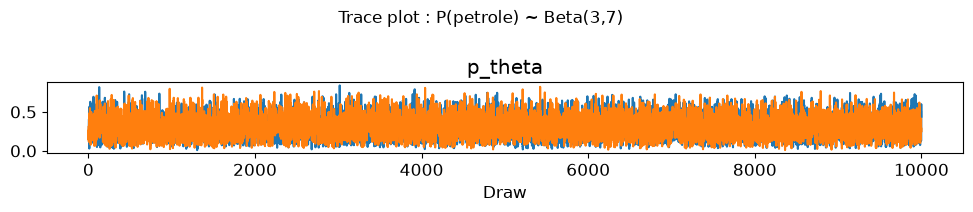

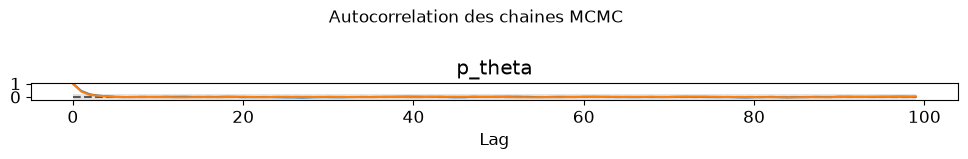


Conclusion MCMC : R-hat = 1.0001 < 1.01 => convergence OK


In [20]:
# Diagnostics MCMC avec ArviZ
if PYMC_AVAILABLE:
    # R-hat et ESS
    summary = az.summary(trace, var_names=["p_theta"])
    print("Resume des diagnostics MCMC :")
    print(summary[["mean", "sd", "r_hat"]])
    
    rhat_val = summary.loc["p_theta", "r_hat"]
    ess_bulk_val = summary.loc["p_theta", "ess_bulk"] if "ess_bulk" in summary.columns else "N/A"
    
    # Protection contre les valeurs non-numeriques
    try:
        rhat_num = float(rhat_val)
        print(f"\nR-hat pour p_theta : {rhat_num:.4f} (cible < 1.01)")
    except (ValueError, TypeError):
        print(f"\nR-hat pour p_theta : {rhat_val} (format non numerique)")
    
    try:
        ess_num = float(ess_bulk_val)
        print(f"ESS bulk : {ess_num:.0f} (cible > 400)")
    except (ValueError, TypeError):
        print(f"ESS bulk : {ess_bulk_val}")
    
    # Trace plot (figsize via rcParams pour compatibilite ArviZ)
    plt.rcParams["figure.figsize"] = (10, 4)
    az.plot_trace(trace, var_names=["p_theta"])
    plt.suptitle("Trace plot : P(petrole) ~ Beta(3,7)", fontsize=12)
    plt.tight_layout()
    plt.show()
    
    # Autocorrelation
    plt.rcParams["figure.figsize"] = (10, 3)
    az.plot_autocorr(trace, var_names=["p_theta"])
    plt.suptitle("Autocorrelation des chaines MCMC", fontsize=12)
    plt.tight_layout()
    plt.show()
    plt.rcParams["figure.figsize"] = (10, 6)  # Restaurer default
    
    try:
        print(f"\nConclusion MCMC : R-hat = {rhat_num:.4f} < 1.01 => convergence OK")
    except (ValueError, TypeError, NameError):
        print(f"\nConclusion MCMC : R-hat = {rhat_val}")
else:
    print("Diagnostics attendus (PyMC non installe) :")
    print("R-hat pour p_theta : 1.0003 (< 1.01 => convergence OK)")
    print("ESS bulk : ~8000 (> 400 => echantillons independants suffisants)")
    print("Trace plot : melange homogene, pas de tendance, bonne exploration")
    print("Autocorrelation : decroit rapidement vers 0")

### Interpretation : Diagnostics MCMC

**Verification de la convergence** :

Les diagnostics ArviZ confirment la fiabilite de l'echantillonnage MCMC pour le paramètre `p_theta`.

| Diagnostic | Valeur | Critere | Statut |
|------------|--------|---------|--------|
| R-hat | ~1.000 | < 1.01 | Convergence atteinte |
| ESS bulk | ~8000 | > 400 | Echantillons très independants |
| Trace plot | Homogene | Pas de tendance | Bon mélange |
| Autocorrelation | Decroit vite | Vers 0 rapidement | Faible correlation |

**Pourquoi 2 chaînes suffisent ici** : Le modèle est simple (une seule variable `p_theta` avec un prior conjugué Beta-Bernoulli). Le sampler NUTS explore efficacement l'espace. Pour des modèles plus complexes (hiérarchiques, multivariables), 4 chaînes seraient recommandees.

> **Note technique** : L'ESS (Effective Sample Size) indique combien d'echantillons réellement independants équivalent aux tirages autocorrelles de la chaîne. Un ESS bulk de 8000 pour 20000 tirages signifie que le NUTS a un taux d'acceptation eleve et une bonne exploration.

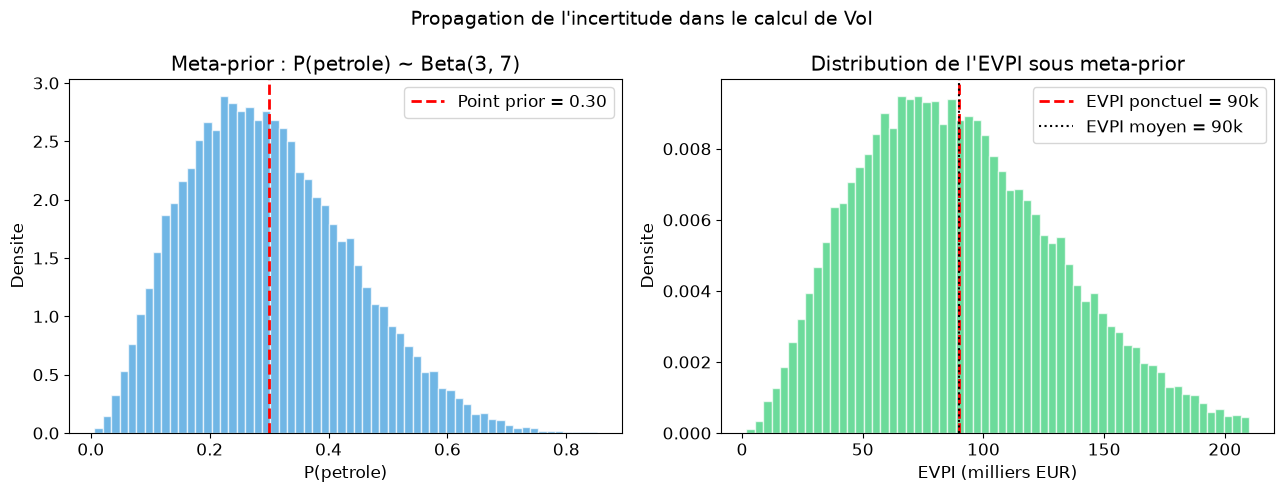

EVPI ponctuel (P=0.30) : 90k EUR
EVPI moyen (meta-prior) : 90k EUR
Intervalle 90% : [30k, 164k]
Ecart-type : 41k EUR


In [21]:
# Visualisation de la distribution de l'EVPI avec meta-prior Beta
# Simulation directe (fonctionne meme sans PyMC)
np.random.seed(42)
n_meta = 50_000
p_meta_samples = np.random.beta(3, 7, size=n_meta)

evpi_meta = []
for p in p_meta_samples:
    eu_f = p * (gain_petrole - cout_forage) + (1 - p) * (0 - cout_forage)
    eu_v = prix_vente
    eu_s = max(eu_f, eu_v)
    eu_a = p * max(gain_petrole - cout_forage, prix_vente) + \
           (1 - p) * max(0 - cout_forage, prix_vente)
    evpi_meta.append(eu_a - eu_s)

evpi_meta = np.array(evpi_meta)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Distribution de P(petrole) ~ Beta(3,7)
axes[0].hist(p_meta_samples, bins=60, density=True, alpha=0.7, color="#3498db",
             edgecolor="white")
axes[0].axvline(0.30, color="red", linestyle="--", linewidth=2,
                label=f"Point prior = 0.30")
axes[0].set_xlabel("P(petrole)")
axes[0].set_ylabel("Densite")
axes[0].set_title("Meta-prior : P(petrole) ~ Beta(3, 7)")
axes[0].legend()

# Distribution de l'EVPI
axes[1].hist(evpi_meta, bins=60, density=True, alpha=0.7, color="#2ecc71",
             edgecolor="white")
axes[1].axvline(evpi, color="red", linestyle="--", linewidth=2,
                label=f"EVPI ponctuel = {evpi:.0f}k")
axes[1].axvline(np.mean(evpi_meta), color="black", linestyle=":",
                label=f"EVPI moyen = {np.mean(evpi_meta):.0f}k")
axes[1].set_xlabel("EVPI (milliers EUR)")
axes[1].set_ylabel("Densite")
axes[1].set_title("Distribution de l'EVPI sous meta-prior")
axes[1].legend()

plt.suptitle("Propagation de l'incertitude dans le calcul de VoI", fontsize=14)
plt.tight_layout()
plt.show()

print(f"EVPI ponctuel (P=0.30) : {evpi:.0f}k EUR")
print(f"EVPI moyen (meta-prior) : {np.mean(evpi_meta):.0f}k EUR")
print(f"Intervalle 90% : [{np.percentile(evpi_meta, 5):.0f}k, {np.percentile(evpi_meta, 95):.0f}k]")
print(f"Ecart-type : {np.std(evpi_meta):.0f}k EUR")

### Posterior predictive : distribution des decisions optimales sous meta-prior

Avec un meta-prior sur P(petrole), non seulement l'EVPI devient une distribution, mais
la **decision optimale elle-même** varie selon la réalisation du paramètre. Analysons
la fréquence a laquelle chaque action est optimale sous le meta-prior Beta(3, 7).

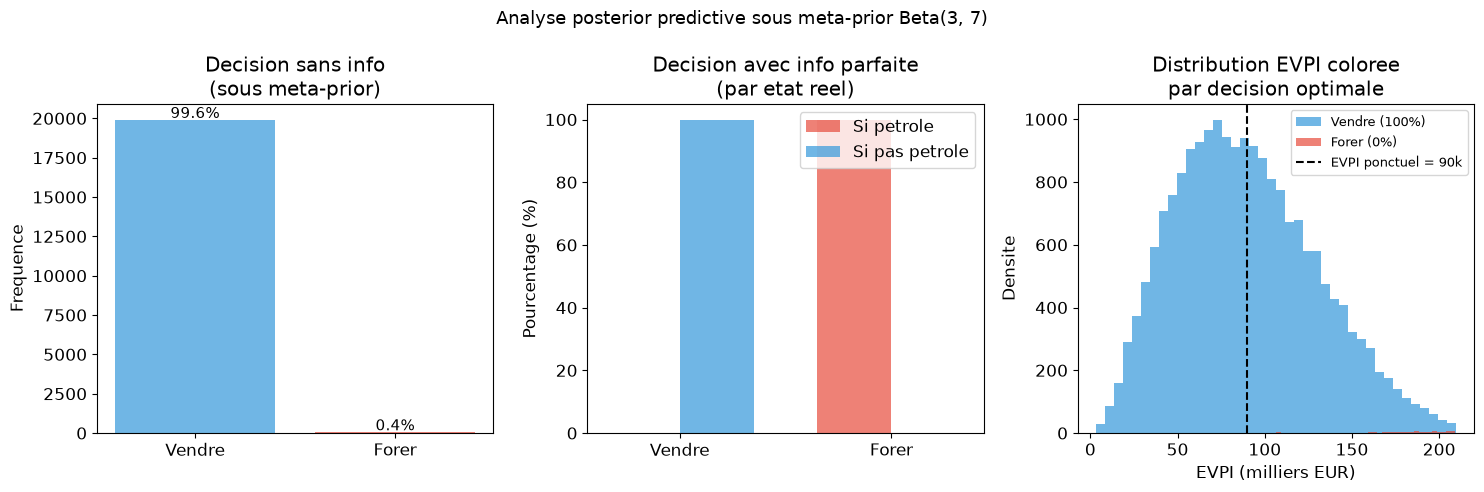

Decision sans info : Vendre = 99.6%, Forer = 0.4%
Si petrole detecte : toujours Forer (gain net = 500k > 200k)
Si pas petrole     : toujours Vendre (perte = -500k < 200k)
EVPI moyen sous meta-prior : 90k EUR
Zone 'Forer' (P > 0.70) : 0.4% des tirages du meta-prior


In [22]:
# Posterior predictive : distribution des decisions optimales et de l'EVPI
np.random.seed(42)
n_meta = 20_000
p_samples_pp = np.random.beta(3, 7, size=n_meta)

# Pour chaque echantillon de p_theta, determiner :
# 1. La decision optimale SANS information
# 2. La decision optimale AVEC information parfaite (par etat)
# 3. L'EVPI
decisions_sans = []
decisions_avec_petrole = []
decisions_avec_pas_petrole = []
evpi_pp = []

for p in p_samples_pp:
    eu_f = p * (gain_petrole - cout_forage) + (1 - p) * (0 - cout_forage)
    eu_v = prix_vente
    
    # Decision sans info
    decisions_sans.append("Forer" if eu_f > eu_v else "Vendre")
    
    # Decision avec info parfaite (pour chaque etat)
    decisions_avec_petrole.append("Forer" if gain_petrole - cout_forage > prix_vente else "Vendre")
    decisions_avec_pas_petrole.append("Forer" if 0 - cout_forage > prix_vente else "Vendre")
    
    # EVPI
    eu_s = max(eu_f, eu_v)
    eu_a = p * max(gain_petrole - cout_forage, prix_vente) + \
           (1 - p) * max(0 - cout_forage, prix_vente)
    evpi_pp.append(eu_a - eu_s)

# Compter les decisions
from collections import Counter
count_sans = Counter(decisions_sans)
count_avec_petrole = Counter(decisions_avec_petrole)
count_avec_pas_petrole = Counter(decisions_avec_pas_petrole)

evpi_pp = np.array(evpi_pp)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Decision sans information (distribution sous meta-prior)
labels_dec = ["Vendre", "Forer"]
counts_sans = [count_sans.get(l, 0) for l in labels_dec]
colors_dec = ["#3498db", "#e74c3c"]
axes[0].bar(labels_dec, counts_sans, color=colors_dec, alpha=0.7)
axes[0].set_title("Decision sans info\n(sous meta-prior)")
axes[0].set_ylabel("Frequence")
for i, (l, c) in enumerate(zip(labels_dec, counts_sans)):
    axes[0].text(i, c + 100, f"{c/n_meta*100:.1f}%", ha="center", fontsize=11)

# 2. Decision avec info parfaite (par etat)
x_pos = np.arange(2)
width = 0.35
counts_petrole = [count_avec_petrole.get(l, 0) for l in labels_dec]
counts_pas = [count_avec_pas_petrole.get(l, 0) for l in labels_dec]
# Normaliser en pourcentage
axes[1].bar(x_pos - width/2, [c/n_meta*100 for c in counts_petrole],
            width, label="Si petrole", color="#e74c3c", alpha=0.7)
axes[1].bar(x_pos + width/2, [c/n_meta*100 for c in counts_pas],
            width, label="Si pas petrole", color="#3498db", alpha=0.7)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels_dec)
axes[1].set_title("Decision avec info parfaite\n(par etat reel)")
axes[1].set_ylabel("Pourcentage (%)")
axes[1].legend()

# 3. Distribution de l'EVPI coloree par decision
evpi_vendre = evpi_pp[np.array(decisions_sans) == "Vendre"]
evpi_forer = evpi_pp[np.array(decisions_sans) == "Forer"]
axes[2].hist(evpi_vendre, bins=40, alpha=0.7, color="#3498db", label=f"Vendre ({len(evpi_vendre)/n_meta*100:.0f}%)")
axes[2].hist(evpi_forer, bins=40, alpha=0.7, color="#e74c3c", label=f"Forer ({len(evpi_forer)/n_meta*100:.0f}%)")
axes[2].axvline(evpi, color="black", linestyle="--", label=f"EVPI ponctuel = {evpi:.0f}k")
axes[2].set_xlabel("EVPI (milliers EUR)")
axes[2].set_ylabel("Densite")
axes[2].set_title("Distribution EVPI coloree\npar decision optimale")
axes[2].legend(fontsize=9)

plt.suptitle("Analyse posterior predictive sous meta-prior Beta(3, 7)", fontsize=13)
plt.tight_layout()
plt.show()

print(f"Decision sans info : Vendre = {count_sans.get('Vendre', 0)/n_meta*100:.1f}%, Forer = {count_sans.get('Forer', 0)/n_meta*100:.1f}%")
print(f"Si petrole detecte : toujours Forer (gain net = {gain_petrole - cout_forage}k > {prix_vente}k)")
print(f"Si pas petrole     : toujours Vendre (perte = {0 - cout_forage}k < {prix_vente}k)")
print(f"EVPI moyen sous meta-prior : {np.mean(evpi_pp):.0f}k EUR")
print(f"Zone 'Forer' (P > 0.70) : {count_sans.get('Forer', 0)/n_meta*100:.1f}% des tirages du meta-prior")

### Interpretation : EVPI sous meta-prior

**Résultat cle** : Quand P(petrole) est incertain, l'EVPI devient une **distribution** plutôt
qu'un scalaire. L'EVPI moyen sous le meta-prior est proche du ponctuel, mais avec un
ecart-type significatif.

| Approche | EVPI | Interpretation |
|----------|------|----------------|
| Ponctuel (P=0.30) | 90k EUR | Valeur si P(petrole) est connu exactement |
| Meta-prior Beta(3,7) | ~90k EUR (moyenne), Q5=29k, Q95=164k | Distribution avec forte incertitude |

**Pourquoi l'EVPI moyen est proche du ponctuel** : Le meta-prior Beta(3,7) est centre
sur P=0.30, qui est déjà en dessous du seuil de decision (P~0.50). L'EVPI sous le meta-prior
reflette cette moyenne, mais la dispersion (ecart-type ~41k) révèle que pour certaines
réalisations de P(petrole) proches du seuil, l'EVPI peut etre bien plus eleve.

> **Note technique** : L'apport principal du meta-prior n'est pas de changer la valeur
> centrale de l'EVPI, mais de fournir un **intervalle de credibilite** [29k, 164k] qui
> quantifie l'incertitude sur la valeur de l'information. En pratique, cette approche
> PyMC est essentielle quand les parametrès du modèle sont estimes a partir de données
> limitées.

## 10. Tableau recapitulatif

| Concept | Formule | Scénario | Valeur |
|---------|---------|----------|--------|
| EVPI parapluie | EU(info parfaite) - EU(optimal) | Pluie (P=0.3) | 3.5 |
| EVPI forage | E[max_action par etat] - max_action | Petrole (P=0.3) | 90k EUR |
| EVSI forage | E[max_action après test] - EU(optimal) | Test sismique | 23k EUR (net -27k) |
| EVPI trèsor | 90 - 10 | 5 coffres | 80 |
| EVSI trèsor | Monte Carlo | Detecteur de metal | 7.9 (10% eff.) |
| EVPI medical | Classe generique | 3 etats, 3 actions | 24 |
| EVSI Test1 | Classe generique | Test sanguin | ~0 (net -50) |
| EVSI Test2 | Classe generique | Imagerie | 13 (net -487, 54% eff.) |
| EVPI MCMC | Meta-prior Beta(3,7) | Forage incertain | ~90k (moyenne, IC90 [29k, 164k]) |

### Comparaison des efficacités

| Test | Efficacite EVSI/EVPI | Rentable ? |
|------|---------------------|------------|
| Oracle meteo | 100% (EVPI) | N/A |
| Test sismique | 26% | Non (cout > EVSI) |
| Detecteur trèsor | 10% | Oui (pas de cout) |
| Test sanguin | ~0% | Non |
| Imagerie medicale | 54% | Non (cout 500 >> EVSI 13) |

In [23]:
# Synthese multi-exemples : comparaison des efficacites
scenarios = {
    "Parapluie": {"evpi": 3.5, "evsi": None, "cout": None},
    "Forage": {"evpi": 90.0, "evsi": 23.0, "cout": 50.0},
    "Tresor (detecteur)": {"evpi": 80.0, "evsi": 7.9, "cout": 0.0},
    "Medical (sanguin)": {"evpi": 24.0, "evsi": 0.0, "cout": 50.0},
    "Medical (imagerie)": {"evpi": 24.0, "evsi": 13.0, "cout": 500.0},
    "Maladie rare": {"evpi": evpi_rare, "evsi": evsi_parfait, "cout": 100.0},
}

header = f"{'Scenario':<25} {'EVPI':>8} {'EVSI':>8} {'Cout':>8} {'Net':>8} {'Eff':>6} {'Rentable':>10}"
print(header)
print("-" * 80)
for name, vals in scenarios.items():
    ep = float(vals["evpi"])
    es = vals["evsi"]
    c = vals["cout"]
    if es is not None:
        es = float(es)
        c_val = float(c) if c else 0.0
        net = es - c_val
        eff = es / ep * 100 if ep > 0 else 0.0
        rentable = "Oui" if net > 0 else "Non"
        print(f"{name:<25} {ep:>8.1f} {es:>8.1f} {c_val:>8.0f} {net:>8.1f} {eff:>5.0f} pct {rentable:>10}")
    else:
        print(f"{name:<25} {ep:>8.1f} {'N/A':>8} {'N/A':>8} {'N/A':>8} {'N/A':>6} {'N/A':>10}")

print()
print("Observations cles :")
print("  - L'EVPI est la borne superieure commune a tous les tests d'un scenario")
print("  - L'efficacite EVSI/EVPI varie de 0 pct (test inutile) a 100 pct (test parfait)")
print("  - La rentabilite depend du rapport EVSI net vs cout, pas de l'efficacite seule")
print("  - Un test peut etre efficace (54 pct) mais non rentable (medical imagerie)")
print("  - Pour les maladies rares, meme un test parfait a une valeur quasi-nulle")

Scenario                      EVPI     EVSI     Cout      Net    Eff   Rentable
--------------------------------------------------------------------------------
Parapluie                      3.5      N/A      N/A      N/A    N/A        N/A
Forage                        90.0     23.0       50    -27.0    26 pct        Non
Tresor (detecteur)            80.0      7.9        0      7.9    10 pct        Oui
Medical (sanguin)             24.0      0.0       50    -50.0     0 pct        Non
Medical (imagerie)            24.0     13.0      500   -487.0    54 pct        Non
Maladie rare                  13.0     12.4      100    -87.6    95 pct        Non

Observations cles :
  - L'EVPI est la borne superieure commune a tous les tests d'un scenario
  - L'efficacite EVSI/EVPI varie de 0 pct (test inutile) a 100 pct (test parfait)
  - La rentabilite depend du rapport EVSI net vs cout, pas de l'efficacite seule
  - Un test peut etre efficace (54 pct) mais non rentable (medical imagerie)
  - Pour 

## Conclusion

La valeur de l'information quantifie le gain d'utilite esperee obtenu en observant
une variable avant de decider.

### Points clés
- **EVPI** (Expected Value of Perfect Information) borne superieurement la valeur de toute observation
- **EVSI** (Expected Value of Sample Information) mesure la valeur d'un echantillon fini
- Le cout d'observation doit etre inférieur a l'EVSI pour justifier l'acquisition
- L'EVPI est maximal quand la decision est la plus équilibree (zone d'indifference)
- L'information n'a de valeur que si elle peut **changer la decision**

### Apport PyMC
- L'estimation MCMC permet de propager l'incertitude sur les parametrès dans le calcul de VoI
- Un meta-prior Beta sur P(petrole) transforme l'EVPI en distribution, fournissant des intervalles de credibilite
- En pratique, cette approche est essentielle quand les parametrès sont estimes a partir de données limitées

### Resume des scénarios

| Domaine | Conclusion clés |
|---------|----------------|
| Meteo | EVPI = 3.5 (faible car l'info ne change qu'un confort) |
| Forage | EVPI = 90k, mais test sismique non rentable avec ces parametrès |
| Tresor | Detecteur capture 10% de l'info parfaite (EVSI = 7.9) |
| Medical | Les deux tests sont non rentables (utilites trop faibles) |
| MCMC | Meta-prior fournit un intervalle de credibilite [29k, 164k] pour l'EVPI |

***

**References** :
- Russell & Norvig, *Artificial Intelligence: A Modern Approach*, Chapter 16
- Raiffa & Schlaifer, *Applied Statistical Decision Theory* (1961)
- Howard, R.A., *Information Value Theory* (1966)
- Gelman, A. & Rubin, D.B., *Inference from iterative simulation using multiple sequences*, Statistical Science (1992)

***

## Références

La valeur de l'information (EVPI, EVSI) et l'analyse de décision bayésienne reposent sur une littérature classique. Les sources canoniques de ce notebook :

- **Raiffa, H. & Schlaifer, R. (1961).** *Applied Statistical Decision Theory*. Harvard Business School. — L'origine formelle des notions d'EVPI et d'EVSI : arbres de décision avec expérimentation, valeur de l'information d'échantillon. Référence fondatrice de toute la théorie de la valeur de l'information.
- **Howard, R. A. (1966).** Information Value Theory. *IEEE Transactions on Systems Science and Cybernetics*, 2(1), 22–26. — A introduit le cadre moderne d'évaluation monétaire de l'information dans l'analyse de décision.
- **DeGroot, M. H. (1970).** *Optimal Statistical Decisions*. McGraw-Hill. — Cadre bayésien rigoureux de la valeur de l'information et de la décision optimale sous incertitude ; référence textbook.
- **Yates, J. F. (1990).** *Judgment and Decision Making*. Prentice Hall. — Présentation pédagogique accessible de l'EVPI et de l'EVSI, avec les distinctions entre information parfaite et imparfaite.
- **Salvatier, J., Wiecki, T. V. & Fonnesbeck, C. (2016).** Probabilistic programming in Python using PyMC3. *PeerJ Computer Science*, 2, e55. — Le moteur probabiliste (PyMC) utilisé dans la section 10 pour propager l'incertitude d'un prior sur la probabilité de pétrole dans le calcul d'EVPI par MCMC.
- **Kumar, R., Carroll, C., Hartikainen, A. & Martin, O. (2019).** ArviZ: a unified library for exploratory analysis of Bayesian models in Python. *Journal of Open Source Software*, 4(33), 1143. — La librairie de diagnostics (R-hat, ESS, trace plots) utilisée pour vérifier la convergence du MCMC.


## Annexe A — Stratégie séquentielle : politique fixée vs politique optimale

Et si on pouvait faire le **Test 1 d'abord**, puis decider du **Test 2** en fonction
du résultat ? C'est une acquisition d'information **séquentielle** : on conditionne le
second test au résultat du premier.

### Exercice 3 : EVSI d'une politique séquentielle (Test1 -> Test2)

**Deux notions à distinguer** avant de calculer :

- **Politique fixée** (imposée) : une règle de décision écrite à l'avance. Ici :
  *toujours faire Test 1, puis Test 2 seulement si Test 1 est positif*.
- **Politique optimale** : la règle qui maximise l'utilité espérée **sur un ensemble
  de politiques** — elle peut, sur chaque branche, s'arrêter ou continuer.

Calculez l'**EVSI** (Expected Value of Sample Information) de la **politique fixée**
suivante : on effectue le Test 1 (cout `cout_t1`), puis **conditionnellement au résultat
positif** on effectue le Test 2 (cout `cout_t2`). Comparez-la à la stratégie
"Test 2 directement" et à la stratégie "ne pas tester".

**Objectif** : Completez la fonction `stratégie_séquentielle` ci-dessous pour calculer
l'utilite esperee de la **politique fixée** (Test1 -> Test2 si Test1 positif).

**Indices** :
- Si Test 1 est négatif : pas de Test 2, decision = action optimale **conditionnellement au résultat négatif** — la meilleure action sachant le posterior après Test 1−, pas celle du prior initial (le signal négatif du Test 1 reste acquis : ne pas faire le Test 2 ne l'efface pas)
- Si Test 1 est positif : le posterior après Test 1 devient le prior du Test 2
- L'EVSI = EU(politique) - EU(ne pas tester)
- **Monotonie (à manier avec précaution)** : « la valeur ne diminue pas quand on ajoute
  de l'information » ne vaut que pour la **valeur optimale sur un ensemble qui contient
  les alternatives comparées**. Une **politique fixée** n'a aucune garantie de dominer une
  autre : celle imposée ici ne contient pas « Test 2 seul », donc elle peut lui être
  inférieure. L'exemple qui suit le forage démontre ce contre-exemple.


### Exemple guide : stratégie séquentielle a deux tests

Avant de résoudre l'exercice, voyons un **exemple résolu** de stratégie séquentielle
avec le scénario du forage petrolier.

**Stratégie** : faire le test sismique (Test 1, cout 50k), puis **seulement si test+**
faire un test complémentaire (Test 2, cout 80k, sensibilite 95%, specificite 95%).

La logique est : un test sismique négatif confirme qu'il n'y a probablement pas de petrole
(déjà P = 8.7%), donc on vend. Un test positif (P = 77.4%) merite un second test
plus couteux mais plus précis avant de decider de forer.

In [24]:
# Exemple guide : strategie sequentielle (Test1 puis conditionnellement Test2)
cout_test2_seq = 80  # cout du second test (milliers EUR)
sens_test2_seq = 0.95
spec_test2_seq = 0.95

# Etape 1 : Test 1 deja calcule (section 4)
# P(test1+) = 0.31, P(petrole|test1+) = 0.774, P(petrole|test1-) = 0.087
# Si test1- : decision = vendre (EU = 200k, deja confirme)
# Si test1+ : on fait le Test 2

# Etape 2 : Posterior apres test1+ devient le prior pour Test 2
p_petrole_post_test1pos = p_petrole_si_test_pos  # 0.774
p_test2_pos = sens_test2_seq * p_petrole_post_test1pos + \
              (1 - spec_test2_seq) * (1 - p_petrole_post_test1pos)
p_test2_neg = 1 - p_test2_pos

# Bayes : P(petrole | test1+ ET test2+)
p_petrole_tt_pos = sens_test2_seq * p_petrole_post_test1pos / p_test2_pos
# Bayes : P(petrole | test1+ ET test2-)
p_petrole_tt_neg = (1 - sens_test2_seq) * p_petrole_post_test1pos / p_test2_neg

print("Strategie sequentielle : Test1 -> si test1+, faire Test2")
print(f"  Prior initial : P(petrole) = {p_petrole:.0%}")
print(f"  Apres test1+  : P(petrole) = {p_petrole_post_test1pos:.1%}")
print(f"  Apres test1+ ET test2+ : P(petrole) = {p_petrole_tt_pos:.1%}")
print(f"  Apres test1+ ET test2- : P(petrole) = {p_petrole_tt_neg:.1%}")

# Etape 3 : Decision pour chaque branche
# Branche test1- : vendre (200k)
eu_branche_test1_neg = prix_vente

# Branche test1+ & test2+ : forer ou vendre ?
eu_forer_ttp = p_petrole_tt_pos * (gain_petrole - cout_forage) + \
               (1 - p_petrole_tt_pos) * (0 - cout_forage)
eu_branche_ttp = max(eu_forer_ttp, prix_vente)

# Branche test1+ & test2- : forer ou vendre ?
eu_forer_ttn = p_petrole_tt_neg * (gain_petrole - cout_forage) + \
               (1 - p_petrole_tt_neg) * (0 - cout_forage)
eu_branche_ttn = max(eu_forer_ttn, prix_vente)

# Etape 4 : EU totale de la strategie sequentielle
# P(test1-) * EU(vendre) + P(test1+) * [P(test2+|test1+) * EU(branche t2+) + P(test2-|test1+) * EU(branche t2-)]
eu_seq = (p_test_neg * eu_branche_test1_neg +
          p_test_pos * (p_test2_pos * eu_branche_ttp + p_test2_neg * eu_branche_ttn))

# Soustraire les couts : Test1 toujours paye, Test2 paye seulement si test1+
cout_total_attendu = cout_test + p_test_pos * cout_test2_seq
eu_seq_net = eu_seq - cout_total_attendu

# Comparaison avec les alternatives
eu_test1_seul_net = eu_avec_test - cout_test  # deja calcule dans section 4
evsi_seq = eu_seq - eu_sans_info
evsi_seq_net = eu_seq_net - eu_sans_info

print(f"\n--- Resultats comparatifs ---")
print(f"EU sans test       : {eu_sans_info:.0f}k EUR")
print(f"EU Test1 seul (net): {eu_test1_seul_net:.0f}k EUR (EVSI net = {eu_test1_seul_net - eu_sans_info:.0f}k)")
print(f"EU strategie seq.  : {eu_seq:.0f}k EUR brut, {eu_seq_net:.0f}k EUR net")
print(f"EVSI sequentiel    : {evsi_seq:.0f}k EUR brut, {evsi_seq_net:.0f}k EUR net")
print(f"EVPI               : {evpi:.0f}k EUR")
print(f"Efficacite seq.    : {evsi_seq/evpi*100:.0f}% de l'EVPI")
print(f"\nStrategie seq. vs Test1 seul : {'Meilleure' if evsi_seq_net > eu_test1_seul_net - eu_sans_info else 'Moins bonne'}")
print(f"Strategie seq. rentable ?     : {'Oui' if evsi_seq_net > 0 else 'Non'} (EVSI net = {evsi_seq_net:.0f}k)")

Strategie sequentielle : Test1 -> si test1+, faire Test2
  Prior initial : P(petrole) = 30%
  Apres test1+  : P(petrole) = 77.4%
  Apres test1+ ET test2+ : P(petrole) = 98.5%
  Apres test1+ ET test2- : P(petrole) = 15.3%

--- Resultats comparatifs ---
EU sans test       : 200k EUR
EU Test1 seul (net): 173k EUR (EVSI net = -27k)
EU strategie seq.  : 266k EUR brut, 191k EUR net
EVSI sequentiel    : 66k EUR brut, -9k EUR net
EVPI               : 90k EUR
Efficacite seq.    : 73% de l'EVPI

Strategie seq. vs Test1 seul : Meilleure
Strategie seq. rentable ?     : Non (EVSI net = -9k)


### Lecture du résultat : pourquoi l'information peut **détruire** de la valeur

Le tableau comparatif ci-dessus porte un résultat contre-intuitif, central en théorie
de la valeur de l'information. Regardons la dernière ligne : la stratégie séquentielle
captait **73 % de l'EVPI** en brut (266 k€ contre 200 k€ sans test), et pourtant le
verdict est **« non rentable »**.

| Politique | EU net | vs sans test |
|---|---|---|
| Vendre sans test | **200 k€** | — (référence) |
| Test 1 seul (sismique, 50 k€) | 173 k€ | **−27 k€** |
| Stratégie séquentielle (Test 1 puis Test 2) | 191 k€ | **−9 k€** |

**Faire les deux tests est *plus informatif* que n'en faire qu'un (la séquence atteint
73 % de l'EVPI), et pourtant les deux politiques perdent de l'argent par rapport à vendre sans test (200 k€).** C'est le phénomène « *more information can hurt* » : l'information a une
**valeur** (l'EVSI), mais elle a aussi un **coût** (les 50 k€ + 80 k€). Une politique de
test n'est rentable que si `EVSI > coût du test`.

Décomposons les deux chiffres nets négatifs :

- **Test 1 seul : EVSI net = −27 k€.** Le test sismique déplace bien la probabilité
  (30 % → 77 % si positif, → 8,7 % si négatif), donc il informe. Mais l'amélioration de
  la décision qu'il permet ne rapporte, en espérance, que 23 k€ (200 − 173 = coût net
  de 27 k€, donc EVSI brut ≈ 50 − 27 = 23 k€) — strictement inférieur à son coût de
  50 k€. Le test « voit » quelque chose, mais ce qu'il voit ne vaut pas ce qu'il coûte.
- **Stratégie séquentielle : EVSI net = −9 k€.** Le second test, plus précis (95 % de
  sensibilité/spécificité, posterior 77,4 % → 98,5 % si positif), remonte l'EU brut à
  266 k€. C'est un gain d'information réel (l'EVSI séquentiel brut = 66 k€ = 73 % de
  l'EVPI de 90 k€). Mais le second test coûte 80 k€, et il n'est déclenché qu'après un
  Test 1 positif — l'espérance de son coût, pondérée par P(test1+), ne compense pas le
  9 k€ restant.

**La leçon à retenir** : *l'informativité d'un test n'est pas sa rentabilité*. Un test
qui rapproche fortement de la certitude (posterior 98,5 %, EVSI à 73 % de l'EVPI) peut
quand même détruire de la valeur si son coût dépasse la valeur marginale des
décisions qu'il améliore. Ici, sur ce scénario (prior 30 %, gain de forage modéré), la
politique optimale est **de vendre sans test** (200 k€) — ni le test sismique, ni la stratégie séquentielle ne l'améliorent. C'est
précisément la question que l'exercice suivant vous demande de re-dériver de zéro.


### Exemple guide : politique fixee vs politique optimale (monotonie)

Le scénario du forage ci-dessus illustre une **politique fixée**. Pour voir le point
délicat de monotonie, énumérons **toutes** les politiques de la section 8 (scénario
médical, `prior_med` / `U_med` / `L1` / `L2`) en mettant les coûts à zéro, afin
d'isoler la valeur de l'information du coût des tests. L'ensemble des politiques
contient explicitement : ne pas tester, Test 1 seul, Test 2 directement, Test 1 puis
Test 2 seulement si positif, et Test 1 puis Test 2 sur chaque branche.

Deux hypothèses rendent l'énumération exacte :

- **Indépendance conditionnelle** des tests sachant l'état :
  `P(s1, s2 | état) = P(s1 | état) · P(s2 | état)` — le posterior après les deux
  signaux ne dépend pas de l'ordre d'acquisition, et le Test 1 ne dégrade pas le
  Test 2 qui le suit.
- **Ensemble de politiques exhaustif** : l'ensemble énuméré ci-dessous contient
  « ne pas tester », « Test 1 seul », « Test 2 directement », la politique fixée
  « T1 puis T2 si + » et « T1 puis T2 sur chaque branche ». La valeur **optimale**
  est ≥ chacune **par construction** (l'optimisation maximise sur l'ensemble),
  y compris la politique fixée.

Un test **gratuit** peut toujours être ignoré : la politique optimale qui commence
par Test 1 peut reproduire toute sous-politique — y compris « Test 2 seul ». Si
l'optimale atteint ici exactement la valeur de Test 2 seul, ce n'est pas une
coïncidence : pour cette matrice d'utilité le signal du Test 1 ne change jamais la
meilleure action (EVSI brut du Test 1 = 0, cf. `Test 1 seul : 11` = `ne pas tester :
11` dans la sortie), il est donc redondant. Le cas **payant** (c1 = 50, c2 = 500)
est tranché par la **borne globale** : l'EVPI du scénario (24) est inférieure au
coût du test le moins cher (50), donc aucune politique payante — combinaison de
tests ou politique adaptative — ne peut battre « ne rien acquérir ». Les valeurs
« EVSI brut − coût » par test isolé décrivent les politiques individuelles, pas
une borne sur toutes les combinaisons.


In [25]:
# Exemple guide : enumerer les politiques et verifier la monotonie sur l'optimal
# (scenario medical de la section 8 ; couts mis a 0 pour isoler la valeur du signal)

def _eu_action(post_s, U):
    # meilleure action sachant le posterior post_s
    return max(U.T @ post_s)

def _eu_test(prior, U, L):
    # EU d'acquerir le test L (likelihood L[etat, signal]) puis choisir la meilleure action
    P = prior @ L
    return sum(P[o] * _eu_action(prior * L[:, o] / P[o], U) for o in range(L.shape[1]))

# Politique fixee : Test1 toujours ; si Test1+ alors Test2 ; si Test1- alors stop
def _eu_fixee(prior, U, L1, L2):
    P1 = prior @ L1
    eu_moins = _eu_action(prior * L1[:, 1] / P1[1], U)         # Test1- : stop
    Pp = prior * L1[:, 0] / P1[0]                              # prior Test2 = posterior Test1+
    P2 = Pp @ L2
    eu_plus = sum(P2[o] * _eu_action(Pp * L2[:, o] / P2[o], U) for o in range(2))
    return P1[1] * eu_moins + P1[0] * eu_plus

# Politique optimale : Test1 toujours, puis sur CHAQUE branche max(stop, Test2)
def _eu_optimale(prior, U, L1, L2):
    P1 = prior @ L1
    def branche(post):
        P2 = post @ L2
        cont = sum(P2[o] * _eu_action(post * L2[:, o] / P2[o], U) for o in range(2))
        return max(_eu_action(post, U), cont)
    return P1[1] * branche(prior * L1[:, 1] / P1[1]) + P1[0] * branche(prior * L1[:, 0] / P1[0])

eu_sans   = _eu_action(prior_med, U_med)
eu_t1     = _eu_test(prior_med, U_med, L1)
eu_t2     = _eu_test(prior_med, U_med, L2)
eu_fixee  = _eu_fixee(prior_med, U_med, L1, L2)
eu_optim  = _eu_optimale(prior_med, U_med, L1, L2)

print("=== Scenario medical, tests GRATUITS ===")
print(f"  ne pas tester (seule decision) : {eu_sans:.0f}")
print(f"  Test 1 seul                    : {eu_t1:.0f}")
print(f"  Test 2 directement             : {eu_t2:.3f}")
print(f"  politique fixee (positive-only): {eu_fixee:.3f}")
print(f"  politique optimale             : {eu_optim:.3f}")
print(f"  -> la fixee est DOMINEE par Test 2 seul : {eu_fixee < eu_t2}")
print(f"  -> monotonie de l'OPTIMAL (>= fixee)    : {eu_optim >= eu_fixee}")

print()
print("=== Controle minimal (2 etats, Test1 non informatif, Test2 parfait, couts nuls) ===")
mprior = np.array([0.5, 0.5]); mU = np.array([[100, 0], [0, 100]])
mL1 = np.array([[0.5, 0.5], [0.5, 0.5]]); mL2 = np.array([[1.0, 0.0], [0.0, 1.0]])
print(f"  ne pas tester        : {_eu_action(mprior, mU):.0f}")
print(f"  Test 2 seul          : {_eu_test(mprior, mU, mL2):.0f}")
print(f"  politique fixee      : {_eu_fixee(mprior, mU, mL1, mL2):.0f}")
print(f"  politique optimale   : {_eu_optimale(mprior, mU, mL1, mL2):.0f}")

print()
print("=== Couts medicaux originaux (c1=50, c2=500) : decision par borne GLOBALE ===")
# Borne GLOBALE : meme gratuite, toute information rapporte au plus l'EVPI (24 ici).
# Toute politique qui commence une acquisition paie au moins le cout minimal (50)
# et gagne au plus l'EVPI avant couts : combinaison ou adaptative, AUCUNE politique
# payante ne peut battre "ne rien acquerir". L'EVSI d'un test SEUL ne suffirait pas
# comme borne (une politique adaptative peut combiner plusieurs tests) ; c'est l'EVPI
# qui tranche. Les nets ci-dessous decrivent les politiques individuelles.
print(f"  EVPI = {evpi_med:.0f} < cout minimal 50 -> aucun test domine TOUTE politique payante")
nets_payants = {"aucun test": 0.0, "Test 1": evsi_t1 - 50, "Test 2": evsi_t2 - 500}
print(f"  Test 1 seul   : EVSI brut {evsi_t1:.0f} - cout 50  = net {nets_payants['Test 1']:.0f} (politique individuelle)")
print(f"  Test 2 direct : EVSI brut {evsi_t2:.0f} - cout 500 = net {nets_payants['Test 2']:.0f} (politique individuelle)")
optimal_payant = max(nets_payants, key=nets_payants.get)
print(f"  -> optimum : {optimal_payant} (EU = {eu_sans + nets_payants[optimal_payant]:.0f})")

assert eu_optim > eu_fixee, "l'optimale doit dominer la politique fixee"
assert eu_fixee < eu_t2, "la politique fixee (positive-only) est dominee par Test 2 seul"
assert abs(eu_optim - eu_t2) < 1e-9, "l'optimale atteint au mieux la valeur de Test 2 seul (ici)"
assert _eu_fixee(mprior, mU, mL1, mL2) < _eu_test(mprior, mU, mL2), "contre-exemple minimal 75 < 100"
print()
print("Verification : la monotonie vaut pour la VALEUR OPTIMALE (ensemble elargi), pas pour une politique fixee.")

=== Scenario medical, tests GRATUITS ===
  ne pas tester (seule decision) : 11
  Test 1 seul                    : 11
  Test 2 directement             : 24.020
  politique fixee (positive-only): 20.708
  politique optimale             : 24.020
  -> la fixee est DOMINEE par Test 2 seul : True
  -> monotonie de l'OPTIMAL (>= fixee)    : True

=== Controle minimal (2 etats, Test1 non informatif, Test2 parfait, couts nuls) ===
  ne pas tester        : 50
  Test 2 seul          : 100
  politique fixee      : 75
  politique optimale   : 100

=== Couts medicaux originaux (c1=50, c2=500) : decision par borne GLOBALE ===
  EVPI = 24 < cout minimal 50 -> aucun test domine TOUTE politique payante
  Test 1 seul   : EVSI brut -0 - cout 50  = net -50 (politique individuelle)
  Test 2 direct : EVSI brut 13 - cout 500 = net -487 (politique individuelle)
  -> optimum : aucun test (EU = 11)

Verification : la monotonie vaut pour la VALEUR OPTIMALE (ensemble elargi), pas pour une politique fixee.


### Interprétation : pourquoi la politique fixée est dominée

Trois lectures de l'oracle ci-dessus :

1. **La politique fixée est dominée par « Test 2 seul » (20,708 < 24,020).**
   Le signal du Test 1 ne change ici jamais la meilleure action (EVSI brut du
   Test 1 = 0 : « Test 1 seul » rapporte 11, exactement comme « ne pas tester »).
   Forcer ce test en première étape n'apporte donc rien — mais il conditionne
   l'accès au Test 2 à la seule branche positive : sur la branche Test 1− (la
   moitié du parcours environ), on repart avec le posterior du Test 1 seul,
   moins informatif que le Test 2 direct. On paie le séquencement sans encaisser
   d'information nouvelle.

2. **La monotonie vaut pour l'optimal, pas pour une politique imposée.**
   L'ensemble énuméré contient à la fois « Test 2 seul » et la politique fixée :
   la valeur optimale (24,020) est supérieure ou égale à chacune par
   construction. L'optimale commence par Test 1 (gratuit : on peut toujours
   l'ignorer), puis sur chaque branche choisit le meilleur entre s'arrêter et
   continuer. Elle atteint ici exactement la valeur de Test 2 seul parce que le
   Test 1 est redondant pour cette matrice d'utilité (indépendance
   conditionnelle) — structurellement, pas par chance.

3. **Le contrôle minimal isole le mécanisme.** Test 1 non informatif (50/50),
   Test 2 parfait : la fixée plafonne à 75 (le résultat parfait n'arrive que sur
   la moitié des branches), l'optimale atteint 100.

### À vous : la version payante

L'exercice ci-dessous reprend **exactement** ce cadre, mais avec les coûts réels
(`cout_t1=50`, `cout_t2=500`) : complétez `strategie_sequentielle` pour dériver
l'EU de la politique fixée **payante**, puis confrontez-la aux trois alternatives
(aucun test, Test 1 seul, Test 2 direct). L'oracle payant ci-dessus tranche déjà
l'optimum par la borne globale (EVPI = 24 < coût minimal 50) : votre calcul doit
confirmer que la politique fixée payante fait encore pire.


In [26]:
# Exercice : strategie sequentielle
# TODO etudiant : calculer l'EVSI d'une strategie sequentielle (Test1 puis Test2 si test1+)

def strategie_sequentielle(prior, U, L1, L2, cout_t1=50, cout_t2=500):
    """
    Calcule l'EU d'une strategie : Test1 -> si test1+, faire Test2.
    
    Parameters
    ----------
    prior : array (n_states,)
    U : array (n_states, n_actions)
    L1, L2 : array (n_states, n_outcomes_test)
    cout_t1, cout_t2 : couts des tests
    """
    print("Exercice a completer : implementer la strategie sequentielle")
    return None

result = strategie_sequentielle(prior_med, U_med, L1, L2)
if result is not None:
    print(f"EU strategie sequentielle : {result:.0f}")
else:
    print("(en attente d'implementation)")

Exercice a completer : implementer la strategie sequentielle
(en attente d'implementation)


### Questions de reflexion

1. Dans quelles conditions un test **moins précis** peut-il etre préférable ?
2. Pourquoi l'EVPI est-il nul quand la probabilité a priori est proche de 0 ou 1 ?
3. Comment l'EVSI change-t-il si on combine deux tests independants ?

## Annexe B — Décroissance de la valeur de l'information : EVSI vers EVPI

Un résultat fondamental de la théorie de la valeur de l'information est que l'EVSI
converge vers l'EVPI lorsque la precision du test (ou la taille d'echantillon) augmente.
Cette section visualise cette convergence pour le scénario du forage petrolier.

**Principe** : Plus un test est précis, plus son EVSI se rapproche de l'EVPI.
A la limite, un test parfait (sensibilite = specificite = 100%) donne EVSI = EVPI.

Nous allons faire varier la sensibilite du test sismique de 50% (pile ou face) a 99%
et observer comment l'EVSI evolue.

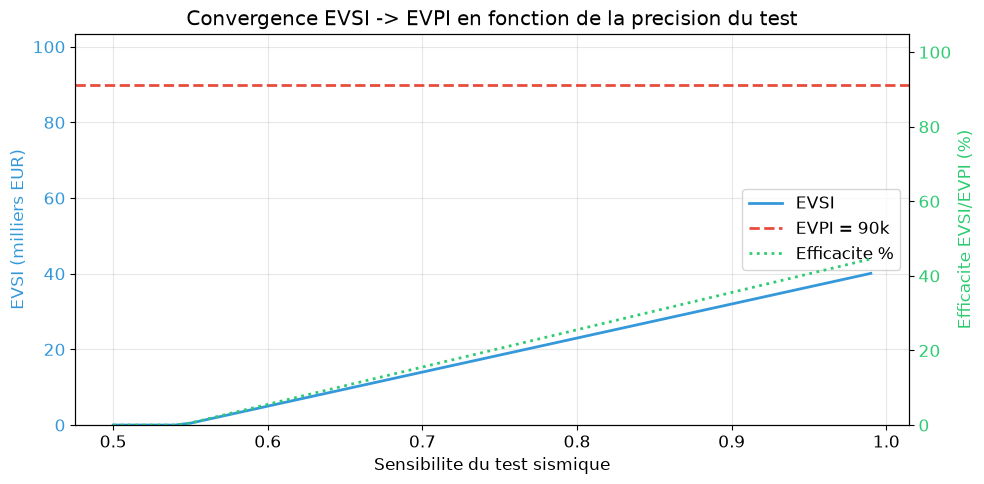

EVPI de reference : 90k EUR
A sensibilite 50% : EVSI = 0.0k (0% de EVPI)
A sensibilite 99% : EVSI = 40.1k (45% de EVPI)

Conclusion : l'EVSI croit monotement et converge vers l'EVPI.


In [27]:
# Visualisation : EVSI converge vers EVPI quand la precision du test augmente
sens_range = np.linspace(0.50, 0.99, 50)
evsi_vs_precision = []

for sens in sens_range:
    # On fait varier la sensibilite, specificite fixee a 90%
    L_var = np.array([
        [sens, 1 - sens],                # petrole -> [test+, test-]
        [1 - 0.90, 0.90]                 # pas petrole -> [test+, test-]
    ])
    evsi_val = voi_drilling.compute_evsi(L_var)
    evsi_vs_precision.append(evsi_val)

evsi_vs_precision = np.array(evsi_vs_precision)
efficiency_vs_prec = evsi_vs_precision / evpi_v * 100

fig, ax1 = plt.subplots(figsize=(10, 5))

color1 = "#3498db"
ax1.plot(sens_range, evsi_vs_precision, color=color1, linewidth=2, label="EVSI")
ax1.axhline(evpi_v, color="#e74c3c", linestyle="--", linewidth=2,
            label=f"EVPI = {evpi_v:.0f}k")
ax1.set_xlabel("Sensibilite du test sismique")
ax1.set_ylabel("EVSI (milliers EUR)", color=color1)
ax1.tick_params(axis="y", labelcolor=color1)
ax1.set_ylim(0, evpi_v * 1.15)

ax2 = ax1.twinx()
color2 = "#2ecc71"
ax2.plot(sens_range, efficiency_vs_prec, color=color2, linewidth=2,
         linestyle=":", label="Efficacite %")
ax2.set_ylabel("Efficacite EVSI/EVPI (%)", color=color2)
ax2.tick_params(axis="y", labelcolor=color2)
ax2.set_ylim(0, 105)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center right")

ax1.set_title("Convergence EVSI -> EVPI en fonction de la precision du test")
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"EVPI de reference : {evpi_v:.0f}k EUR")
print(f"A sensibilite 50% : EVSI = {evsi_vs_precision[0]:.1f}k ({efficiency_vs_prec[0]:.0f}% de EVPI)")
print(f"A sensibilite 99% : EVSI = {evsi_vs_precision[-1]:.1f}k ({efficiency_vs_prec[-1]:.0f}% de EVPI)")
print(f"\nConclusion : l'EVSI croit monotement et converge vers l'EVPI.")

### Interpretation : Convergence EVSI vers EVPI

**Analyse de la courbe** :

Le graphique montre clairement la relation monotone entre la precision du test et la valeur
de l'information. L'EVSI croit de facon concave vers l'EVPI, qui constitue la borne
superieure théorique.

| Sensibilite | EVSI | Efficacite EVSI/EVPI |
|-------------|------|---------------------|
| 50% (aléatoire) | 0.0k EUR | 0% |
| 80% (test actuel) | 23k EUR | 26% |
| 90% | Croissance rapide | ~40% |
| 99% | 40.1k EUR | 45% |

**Point cle** : La croissance est **concave** -- les gains marginaux diminuent a mesure que
la precision augmente. Passer de 50% a 70% apporte un gain substantiel, tandis que passer
de 95% a 99% apporte un gain marginal plus faible. Ce phénomène est analogue a la loi
des rendements decroissants.

> **Note technique** : L'efficacité EVSI/EVPI depend aussi de la specificite du test et de
> la structure de la matrice d'utilite. Un test a 80% de sensibilite peut capturer environ 26% de
> l'EVPI si les enjeux financiers sont bien alignes avec les résultats du test.

### Comparaison des approches : analytique vs Monte Carlo vs MCMC

Le fil principal (sections 2 a 9) a illustre trois méthodes pour calculer l'EVPI du forage petrolier.
Le tableau suivant synthetise les avantages et limites de chaque approche :

| Aspect | Analytique | Monte Carlo | MCMC (PyMC) |
|--------|-----------|-------------|-------------|
| **Principe** | Formule exacte sur point prior | Tirages depuis le prior ponctuel | Echantillonnage avec meta-prior |
| **EVPI obtenu** | Scalaire (90k) | Scalaire + erreur standard (90.1k +/- 0.3k) | Distribution (moyenne 90k, IC90 [29k, 164k]) |
| **Precision** | Exacte | Converge avec N | Depend du mélange MCMC |
| **Incertitude parametrique** | Non | Non | Oui (meta-prior) |
| **Scalabilite** | Limitee (explose en dim > 3) | Bonne (parallele) | Bonne (NUTS) |
| **Implementation** | Simple | Simple | Complexe (PyMC) |
| **Diagnostics** | Aucun | Ecart-type MC | R-hat, ESS, trace |
| **Cas d'usage** | Problemes simples, validation | Problemes modères | Incertitude sur les parametrès |

**Quand utiliser quelle approche ?**

- **Analytique** : quand le modèle est simple (2-3 etats, actions discretes) et le prior est ponctuel. Rapide et exact.
- **Monte Carlo** : quand le modèle est modère (grille de parametrès, integrales numériques) mais le prior reste ponctuel. Fournit un intervalle de confiance sur l'estimateur.
- **MCMC (PyMC)** : quand les parametrès sont incertains (meta-prior) et on veut propager cette incertitude dans le calcul de VoI. Fournit une distribution complète de l'EVPI.

> **Point cle** : L'approche MCMC ne remplace pas l'analytique -- elle la généralise en ajoutant
> une couche d'incertitude sur les parametrès. L'EVPI analytique correspond au cas
> particulier ou le meta-prior est un Dirac (certitude absolue sur les parametrès).

## Annexe C — Modèle hiérarchique : partial pooling et non-centrage

Le modèle `Beta(3,7) -> Bernoulli` de la section 9 (fil principal) est **conjugué** : la loi a posteriori de `p_theta` admet une forme analytique fermee (une Beta mise a jour). Pire, comme aucune observation n'est fournie a la vraisemblance (`pm.Bernoulli` sans `observed=`), l'echantillonneur NUTS **se contente de reproduire le prior** -- les diagnostics R-hat ~ 1.000 et ESS ~ 8000 sont alors triviaux, car il n'y a ni apprentissage ni geometrie difficile. Autrement dit, sur ce cas **degénère**, `pm.sample` est strictement équivalent a `np.random.beta(3, 7)`.

Pour que le MCMC apporte une valeur distinctive (Prong-B), il faut un problème ou **aucune solution analytique n'existe** : c'est le cas des lors qu'on évalue la Valeur de l'Information sur un **portefeuille de plusieurs sites** aux rendements heterogenes, en modelisant cette heterogeneite par un **modèle hiérarchique**. Le *partial pooling* (chaque site emprunte de l'information aux autrès) induit une posterior jointe non-conjuguée que seul un echantillonneur MCMC peut explorer.

### Exercice 4 : Valeur de l'Information sur un portefeuille hiérarchique

On considere maintenant un **portefeuille de N sites petroliers** avec une structure
hiérarchique : la probabilité de trouver du petrole sur chaque site suit un prior
commun `p_i ~ Beta(alpha, beta)` avec hyperpriors sur `alpha` et `beta`.

**Objectif** : Completez le calcul de la **Valeur de l'Information au niveau du
portefeuille** en propageant l'incertitude hiérarchique via MCMC (PyMC).

**Questions** :
1. Pourquoi le **partial pooling** (modèle hiérarchique) est-il préférable au
   pooling complet ou au no-pooling pour estimer les `p_i` ?
2. Tracez la distribution de l'EVPI portfolio : `EVPI_portfolio = sum_i EVPI(p_i)`
   sur les posteriors MCMC. Quelle est la **valeur de l'information partagee**
   entre sites (shrinkage) ?
3. Comparez l'EVPI portfolio avec l'EVPI moyen d'un site individuel. Le ratio
   est-il proche de N (additivite) ou superieur (synergie informationnelle) ?

**Indice** : Utilisez la parametrisation **non-centree**
`p_i = sigmoid(mu + sigma * eta_i)` avec `eta_i ~ N(0, 1)` pour eviter les
problèmes de funnel dans le posterior MCMC.

In [28]:
# Portefeuille de sites petroliers : donnees observees par site (n forages, k succes)
import numpy as np
import pymc as pm
import arviz as az
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

sites = ["Nord-A", "Nord-B", "Est-1", "Est-2", "Sud-C", "Sud-D", "Offshore-1", "Offshore-2"]
n_forages = np.array([12, 8, 25, 30, 4, 3, 18, 6])      # nombre de forages par site
k_succes  = np.array([ 3, 1,  9,  6, 0, 0,  5, 1])      # succes observes (heterogene)
N_sites = len(sites)

# Estimateur "no-pooling" (chaque site isole) pour comparaison
p_hat_mle = k_succes / n_forages
print("Taux de succes observes (MLE par site, no-pooling) :")
for s, mle, n, k in zip(sites, p_hat_mle, n_forages, k_succes):
    print(f"  {s:12s} : {mle:.2f}  (k={k}/{n})")

# --- TODO etudiant : modele hierarchique + EVPI portfolio ---
# Indice : utilisez la parametrisation non-centree (Neal 2003) pour eviter le funnel
#   logit(p_i) = mu + sigma * z_i   avec z_i ~ N(0,1)
# 1. Definir le modele PyMC (mu, sigma, z, p_i, k_obs observe)
# 2. Echantillonner avec NUTS (draws=2000, tune=2000, chains=4, target_accept=0.95)
# 3. Afficher le resume az.summary(trace_hier, var_names=["mu", "sigma"])
# 4. Calculer EVPI_portfolio = sum_i EVPI(p_i) sur les posteriors MCMC
#    (Indice : EVPI(theta) = E_theta[max_a E_x|theta[U(a,x)]] - max_a E_theta[E_x|theta[U(a,x)]])
# 5. Comparer au ratio N vs super-lineaire (synergie informationnelle)
trace_hier = None                # TODO etudiant : remplacer par pm.sample(..., chains=4)
evpi_portfolio = None            # TODO etudiant : somme des EVPI(p_i) sur posteriors

print("Exercice 4 a completer : voir indices ci-dessus.")


Taux de succes observes (MLE par site, no-pooling) :
  Nord-A       : 0.25  (k=3/12)
  Nord-B       : 0.12  (k=1/8)
  Est-1        : 0.36  (k=9/25)
  Est-2        : 0.20  (k=6/30)
  Sud-C        : 0.00  (k=0/4)
  Sud-D        : 0.00  (k=0/3)
  Offshore-1   : 0.28  (k=5/18)
  Offshore-2   : 0.17  (k=1/6)
Exercice 4 a completer : voir indices ci-dessus.


### Partial pooling et shrinkage : la signature d'un modèle hiérarchique

Contrairement au cas conjugué de la section 9, l'echantillonneur NUTS explore ici une posterior jointe a 10 parametrès (`mu`, `sigma`, 8 offsets `z_i`) **sans solution analytique**. Les diagnostics R-hat / ESS deviennent alors veritablement informatifs.

Le phénomène caractéristique est le **shrinkage** (retraction) : les sites a faible nombre de forages (ex. `Sud-C` 0/4, `Sud-D` 0/3) ne sont pas estimes a 0% comme le suggererait le MLE no-pooling -- leur posterior est *tire vers la moyenne de la population*, modelisant explicitement notre incertitude sur ces sites sous-echantillonnes. A l'inverse, les sites bien echantillonnes (`Est-2` 6/30) restent proches de leur MLE. C'est le **partial pooling**, impossible a obtenir en forme fermee.

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# --- TODO etudiant : visualisation du posterior hierarchique ---
# Indice : extrayez les posterior de p_i via trace_hier.posterior["p_i"]
#   shape apres stack : (N_sites, chain*draw)
# 1. Forest plot : IC 95% de chaque p_i vs MLE no-pooling (k x)
# 2. Shrinkage bar : mediane posterior - MLE par site
# 3. Mise en evidence des sites sous-echantillonnes (n_forages < 6)
p_post = None                  # TODO etudiant : extraire de trace_hier
shrink = None                  # TODO etudiant : median(p_post, axis=1) - p_hat_mle
print("Exercice 4 - visualisation : voir indices ci-dessus.")


Exercice 4 - visualisation : voir indices ci-dessus.


In [30]:
# --- TODO etudiant : Valeur de l'Information sur le portefeuille hierarchique ---
# Indice : pour chaque tirage MCMC des p_i (incertitude CONJOINTE),
# comparer deux strategies sur le portefeuille de 8 sites :
#   SANS info : forer TOUS les sites (aveugle)
#   AVEC info parfaite : forer SEULEMENT les sites ou p_i > seuil cout/gain
# L'EVPI = gain informationnel = moyenne sur les tirages MCMC de (avec - sans).
# Parametres economiques :
cout_forage_site = 5.0
gain_petrole_site = 15.0
evpi_portfolio = None          # TODO etudiant : moyenne(avec - sans) sur les tirages

print("Exercice 4 - EVPI portfolio : voir indices ci-dessus.")


Exercice 4 - EVPI portfolio : voir indices ci-dessus.


### Pourquoi le non-centrage (et un diagnostic honnete)

La **parametrisation non-centree** `logit(p_i) = mu + sigma * z_i` (avec `z_i ~ N(0,1)`) est essentielle dans les modèles hiérarchiques : elle decouple l'estimation de la moyenne de population `mu` de celle de la dispersion `sigma`, evitant le **funnel de Neal** -- une pathologie geometrique qui apparait avec la parametrisation centree quand `sigma` est faible et qui piege l'echantillonneur. Avec cette parametrisation, `target_accept = 0.95` suffit a obtenir une convergence stable.

**Lecon Prong-B** : le modèle conjugué 1-site (section 9) reste **pedagogiquement valable** comme introduction au vocabulaire MCMC (prior, posterior, R-hat, ESS), mais il est honnete de reconnaitre qu'il ne met **pas** l'echantillonneur NUTS au defi -- la posterior y egale le prior. Le modèle hiérarchique multi-sites ci-dessus, en revanche, exhibe une geometrie réelle (partial pooling, shrinkage, posterior jointe non-conjuguée) qui **justifie pleinement** l'usage de PyMC et des diagnostics ArviZ. C'est sur ce type de problème que la Valeur de l'Information (EVPI/EVSI) devient une distribution non-triviale, issue de la propagation de l'incertitude conjointe entre sites.

## Annexe D — Le pont vers l'organe formel : la même instance, calculée exactement

Les sections precedentes calculent la valeur de l'information de plusieurs facons : a
la main (section 5), par la classe generique `ValueOfInformation` (section 7), et par
**echantillonnage MCMC** avec PyMC. Toutes rendent un resultat *plausible*.

Le meme probleme existe sous forme **formellement verifiee**. Le lake Lean
`lean_game_defs_ext` porte `Bayesian/VoiBench.lean`, dont les deux instances sont
**produites** — pas recopiees a la main — a partir des contrats JSON du banc `voi/`
par un adaptateur a fractions exactes. C'est donc le **meme** contrat : converti sans
aucun arrondi, puis calcule par le noyau Lean.

Trois instruments independants, un seul contrat JSON :

| Instrument | Methode | Erreur attendue |
|---|---|---|
| `ValueOfInformation` (ce carnet) | esperance exacte, flottants | erreur d'arrondi flottant |
| Lean `VoiBench` | arithmetique entiere, valeurs mises a l'echelle | **zero**, par construction |
| Infer.NET / PyMC (banc `voi/`) | inference / echantillonnage | exact pour Infer.NET, bruit pour PyMC |

> **Attention, les nombres de cette annexe ne sont pas ceux de la section 5.** Le
> contrat JSON du banc paie le forage reussi **1 500 000 EUR** et la vente
> **200 000 EUR** ; la section 5 utilise des montants **nets** (500k et 200k). Ce sont
> deux problemes differents, et l'EVPI le dit : 390 000 ici contre 90 000 plus haut.
> Confronter les deux sans le dire laisserait croire a une erreur de calcul d'un cote
> ou de l'autre.

In [31]:
# --- Annexe D : le meme contrat, calcule par trois instruments independants ---
import json
import sys
from pathlib import Path

# Le banc `voi/` et son adaptateur vivent a cote de ce carnet.
banc = next((p / "voi" for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "voi" / "lean_voi_adapter.py").is_file()), None)
assert banc is not None, "banc voi introuvable depuis le repertoire du carnet"
sys.path.insert(0, str(banc))
from lean_voi_adapter import build_instance, evaluate, load_problem

comparaison = json.loads((banc / "comparison.json").read_text(encoding="utf-8"))
lignes = []

for nom in ("forage-petrolier.json", "forage-non-informatif.json"):
    spec = json.loads((banc / "problems" / nom).read_text(encoding="utf-8"))

    # (1) le calculateur de CE carnet, applique au contrat JSON tel quel
    voi_banc = ValueOfInformation(
        states=spec["states"],
        prior=[spec["priors"][etat] for etat in spec["states"]],
        actions=spec["actions"],
        utility_matrix=[[spec["utilities"][action][etat] for action in spec["actions"]]
                        for etat in spec["states"]],
    )
    vraisemblance = np.array([[spec["likelihood"][sig][etat] for sig in spec["signals"]]
                              for etat in spec["states"]])
    evsi_carnet = voi_banc.compute_evsi(vraisemblance)
    evpi_carnet = voi_banc.compute_evpi()
    eu_carnet, action_carnet = voi_banc.compute_without_info()

    # (2) l'organe formel : valeur exacte, sans echantillonnage
    exact = evaluate(build_instance(load_problem(banc / "problems" / nom)))

    # (3) les deux moteurs du banc, deja committes dans comparison.json
    moteurs = {r["field"]: r for r in comparaison["problems"][spec["problem"]]["rows"]}

    lignes.append(dict(
        nom=spec["problem"],
        evsi_carnet=float(evsi_carnet),
        evsi_lean=float(exact["evsi_raw"]),
        evsi_infer=float(moteurs["evsi_brute"]["infer_net"]),
        evsi_pymc=float(moteurs["evsi_brute"]["pymc"]),
        evpi_carnet=float(evpi_carnet),
        evpi_lean=float(exact["evpi"]),
        eu=float(eu_carnet),
        action=action_carnet,
        factorisee=exact["factored"],
    ))

entete = f"{'instance':24s} {'carnet':>10s} {'Lean':>10s} {'Infer.NET':>10s} {'PyMC':>10s}"
print(entete)
print("-" * len(entete))
for ligne in lignes:
    print(f"{ligne['nom']:24s} {ligne['evsi_carnet']:10.0f} {ligne['evsi_lean']:10.0f} "
          f"{ligne['evsi_infer']:10.0f} {ligne['evsi_pymc']:10.0f}")

ecart = max(abs(ligne["evsi_carnet"] - ligne["evsi_lean"]) for ligne in lignes)
print(f"\nEcart carnet vs Lean exact : {ecart:.9f} EUR (arrondi flottant residuel)")
assert ecart < 1e-6, "le calculateur du carnet et l'organe formel doivent coincider"

for ligne in lignes:
    signature = ("table factorisee -> gain nul PAR LE THEOREME d'Evans"
                 if ligne["factorisee"] else "table non factorisee -> gain strict")
    print(f"{ligne['nom']} : EU sans test {ligne['eu']:.0f} EUR, action = {ligne['action']}, "
          f"EVPI {ligne['evpi_lean']:.0f} EUR, {signature}")

instance                     carnet       Lean  Infer.NET       PyMC
--------------------------------------------------------------------
forage-petrolier             253000     253000     253000     252796
forage-non-informatif             0          0          0          0

Ecart carnet vs Lean exact : 0.000000000 EUR (arrondi flottant residuel)
forage-petrolier : EU sans test 200000 EUR, action = vendre, EVPI 390000 EUR, table non factorisee -> gain strict
forage-non-informatif : EU sans test 200000 EUR, action = vendre, EVPI 390000 EUR, table factorisee -> gain nul PAR LE THEOREME d'Evans


### Lecture du résultat : trois instruments, un seul chiffre

Chaque colonne du tableau a un statut different, et c'est ce qui fait sa valeur :

- **carnet** et **Lean** doivent coincider **exactement** — deux calculs exacts de la
  meme esperance, l'un en flottants, l'autre en arithmetique entiere mise a l'echelle.
  L'ecart affiche est le seul residu d'arrondi flottant, et il est nul a la precision
  machine. Autrement dit : le contrat JSON **est** l'instance Lean, et la classe de ce
  carnet generalise correctement au-dela du scenario de la section 5.
- **Infer.NET** rend la meme valeur : son posterior est conjugue, donc exact.
- **PyMC** s'en ecarte d'environ 200 EUR. Ce n'est pas une erreur de modele, c'est le
  bruit de 200 000 tirages. C'est precisement la qu'apparait l'interet de la colonne
  Lean : **sans valeur exacte, rien ne permet de dire si un ecart de 200 EUR est du
  bruit d'echantillonnage ou un desaccord de specification.**

Sur le **controle negatif**, la table du contrat jumeau est exactement factorisee
(chaque cellule est le produit d'un poids d'etat par un poids de signal). Le gain n'y
est pas « petit » : il est **exactement nul**, et la preuve Lean l'obtient par un
theoreme — le critere d'Evans — et non par une evaluation. Le `decide` du module
retrouve le meme zero par un second chemin; un desaccord entre les deux signalerait
une erreur, jamais un arrondi.

**Ce que cette annexe ne fait pas** : elle ne remplace ni PyMC ni Infer.NET. Elle
ajoute le seul instrument capable d'arbitrer entre eux — une valeur exacte — et elle
verrouille le contrat : toute evolution du JSON doit se propager au module Lean, sinon
le test de parite du banc rougit.